# 📋 Lab 03: Evaluating Structured Outputs in 2026

## Module 03 — The JSON is always valid now. Is it *right*? ✅

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/03-structured-outputs-lab.ipynb)

| | |
|---|---|
| ⏱️ **Time** | 45–55 min core, plus optional extensions · +30 min for the five 🏆 challenges |
| 🎚️ **Level** | Intermediate: Python dicts, JSON, a little Pydantic |
| 🔑 **Keys needed** | None. Fully offline (`PROVIDER = "mock"`); real OpenAI / Anthropic calls are an opt-in switch |
| 🧰 **Tools** | `pydantic` · `jsonschema` · `pandas` · `matplotlib` |
| ✍️ **You'll write** | Five predictions (scored at the end), impact weights (Task 4), your own audit verdicts (Task 7), business-rule validators (Task 8), your own perturbations (Task 9). Each has a safe default, so *Run All* always works |
| 🎛️ **You'll play** | 🕵️ *You're the auditor* (Task 7) and a cost-of-errors simulator (Task 10) |
| 🏁 **You'll leave with** | Field-, record- and null-level metrics, an audited answer key, and an evidence-based SHIP / BLOCK call |

> ### 🕵️ The mystery
> Last quarter your accounts-payable team moved its invoice extractor to **native structured outputs**. The dashboard has been green ever since: **100% of responses are schema-valid**. Then the month-end close (the monthly check that the books balance) turns up a Canadian-dollar invoice booked in US dollars, a tax line overstated by $27.57, and a purchase-order (PO) number copied from another vendor's invoice.
>
> **Would you ship the next model version on the strength of that dashboard?** By the end of this lab you'll know what it was hiding, and you'll have built the metrics that would have caught it.

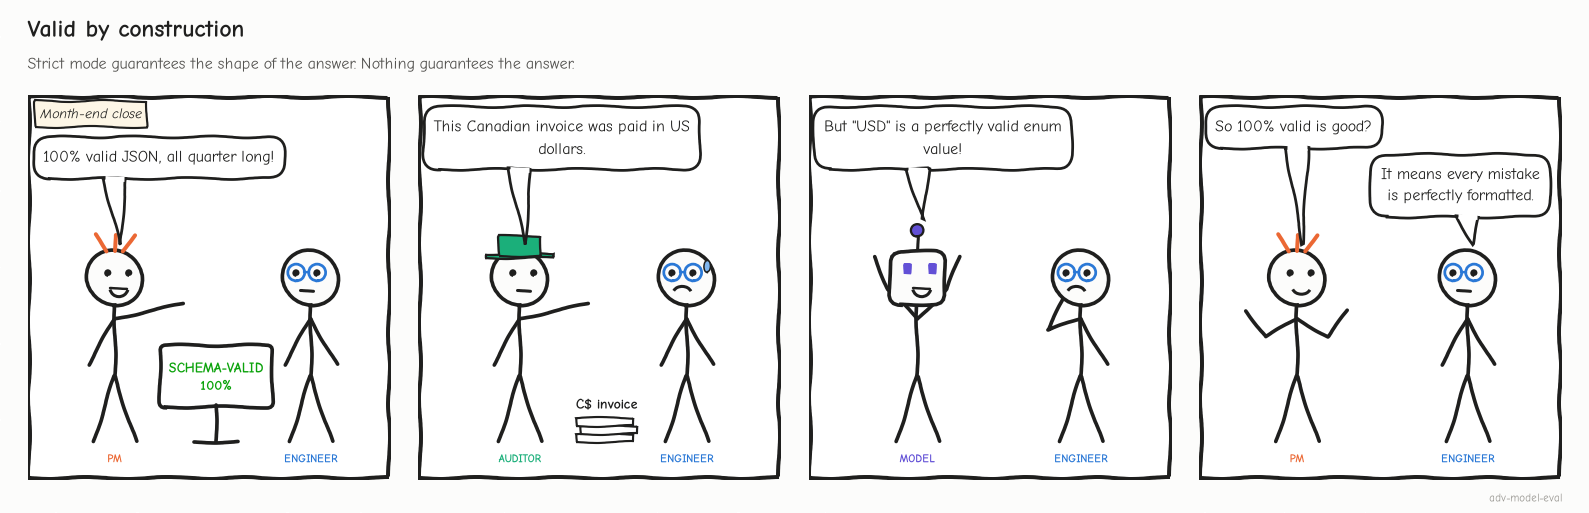

<sub>🖼️ *Valid by construction: the schema guarantees the shape of the answer, not the answer.*</sub>

---

## 🧭 Overview

Until 2024 the hard part was getting valid JSON. **Native structured outputs** (*strict mode*) from OpenAI (`responses.parse`), Anthropic (`messages.parse` / `output_config.format`) and Gemini (response schemas) solved that with **constrained decoding**: at every **token** (the word-pieces a model writes one at a time) the provider blocks any choice that would break your schema, so the output is valid by construction.

That splits quality in two:

- **Schema-valid**: right keys, types and allowed values. Strict mode guarantees it.
- **Value-correct**: the values printed on the document. Nothing guarantees it, and that is where the errors moved.

You'll evaluate 20 strict-mode invoice extractions with six checks at three costs (free; label-free but hand-written; labelled). Each finds what the previous one missed.

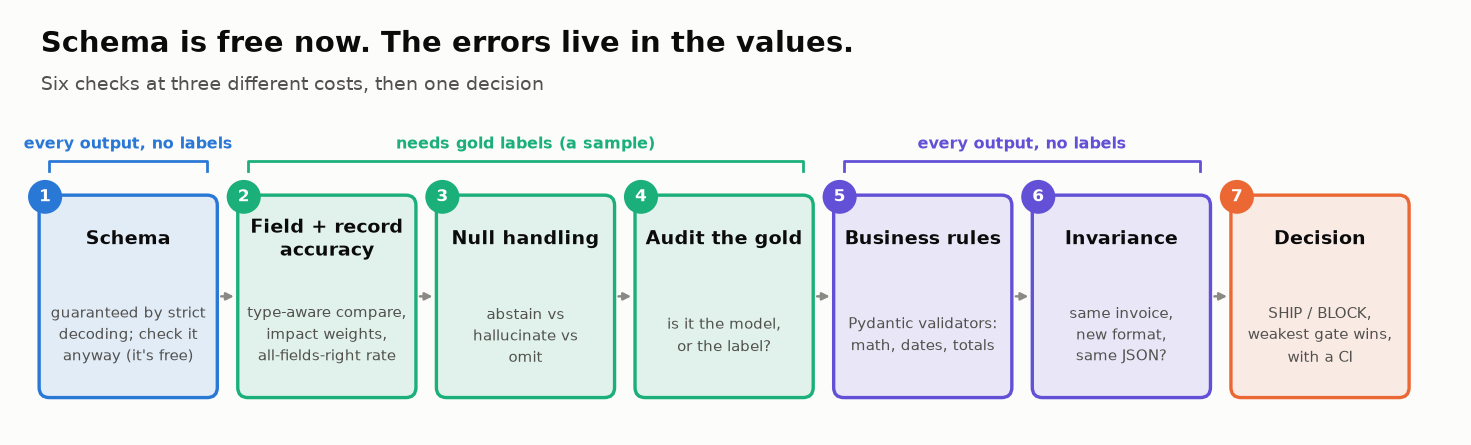

<sub>🖼️ *🗺️ Your route through the lab. Schema is free now; the errors live in the values. Six checks at three costs, then one decision.*</sub>

<details><summary>📖 Jargon decoder: 26 terms this lab uses (click to open)</summary>

| Term | Plain-English meaning | Where you'll meet it |
|---|---|---|
| **Token** | A word-piece. Models write text one token at a time | Overview, Task 2 |
| **Structured outputs / strict mode** | A provider feature that forces the response to match a schema you supply | Overview, Task 2 |
| **Constrained decoding** | How strict mode works: before each token, every choice that would break the schema is masked out | Task 2 diagram |
| **JSON Schema** | A standard JSON document declaring which keys, types and values a record may have | Task 3 |
| **Pydantic model** | A Python class that declares typed fields, validates data, and exports a JSON Schema | Tasks 2, 8 |
| **Nullable vs optional** | Nullable: the key is always there, its value may be `null`. Optional: the key may be missing. Strict mode wants every key, so absence is `null` | Tasks 2, 6 |
| **Gold labels (answer key)** | Human-written correct values for each invoice | Tasks 2, 5, 7 |
| **Comparator** | The function that decides whether a predicted value equals the gold value | Task 5 |
| **Normalisation** | Rewriting both values to one canonical form before comparing (lowercase, no punctuation, no "LLC") | Task 5 |
| **Field / record / critical-record accuracy** | Share of (invoice, field) slots right / share of invoices with every field right / every *critical* field right | Task 5 |
| **95% confidence interval (CI); Wilson interval** | The range of true rates consistent with what you measured; Wilson's formula stays honest at small n | Tasks 5, 10 |
| **OCR** | Optical character recognition: turning a scan into text. Source of `l`-for-`I` and `O`-for-`0` typos | Tasks 5, 9 |
| **Hallucination / abstention / omission** | A value invented for an empty field / a correct `null` / a printed value returned as `null` | Task 6 |
| **Payment terms** | When the bill is due. *Net 30*: 30 days after the invoice date. *Due on receipt*: immediately | Task 6 |
| **Purchase order (PO)** | The buyer's approved order, with its own number | Hook, Task 6 |
| **Three-way match** | Accounts-payable control: pay only if invoice, PO and goods receipt agree | Scenario, Task 6 |
| **Label error** | The answer key is wrong, not the model | Task 7 |
| **Locale** | A country's conventions for dates and numbers: `04/03` is 4 March in London, April 3 in Austin | Tasks 7, 9 |
| **Business rule (validator)** | A relationship every valid invoice obeys (`total = subtotal + tax`), checked in code on every output | Task 8 |
| **Vendor master** | The company's reference list of approved vendors (name, country, currency, bank details) | Task 8, Challenge 2 |
| **Invariance (metamorphic) test; perturbation** | Re-render the same invoice in another format (the perturbation); the extraction must not change | Task 9 |
| **CI (continuous integration)** | The automated tests that run on every code change. Not the confidence interval | Task 9, Stretch |
| **Release gate** | A pass/fail threshold; a release ships only if every gate passes | Task 10 |
| **Accounts payable (AP)** | The team and system that pay vendor invoices | Scenario |
| **General ledger** | The company's master record of every transaction; invoices are "posted" to it | Scenario |
| **Mock provider** | Recorded model outputs replayed offline, so everyone gets the same numbers | Setup |

</details>

## 🎯 Learning Objectives

By the end of this lab you will be able to:

1. **Produce** schema-guaranteed extractions with a Pydantic model and native structured outputs, and **explain** why schema validity is no longer a quality metric.
2. **Score** extractions at the **field** and **record** level with type-aware comparators and business-impact weights.
3. **Measure null handling**: correct abstention vs. hallucinated values vs. omissions.
4. **Audit the answer key** and separate model errors from gold-label errors.
5. **Encode** business rules as Pydantic validators that run on every output without labels, and **name** what they can't catch.
6. **Run invariance tests** that expose silent failures under harmless formatting changes.
7. **Turn** the evidence into a SHIP / BLOCK decision that carries its uncertainty.

## 📋 Prerequisites

- Modules 01–02 (evaluation foundations, failure analysis)
- Reading JSON; Python dicts, loops and f-strings
- Helpful but not required: Pydantic `BaseModel` basics

## ⏱️ Estimated Time

**45–55 minutes** for the core path. Your own perturbations in Task 9, the Stretch Goals and the Exercises are optional.

| Tasks | Minutes |
|---|---|
| 1–3 Setup, the batch, schema validation | 10 |
| 4–5 Weights, field and record accuracy | 10 |
| 6–7 Null handling, the auditor game, gold audit | 12 |
| 8–10 Business rules, invariance, decision and its cost | 18 |

## ⚙️ Environment and Setup

- Runs in **Google Colab** or any Jupyter with Python ≥ 3.10. The only install is `jsonschema`; Colab already has `pydantic`, `pandas` and `matplotlib`.
- **No API keys.** `PROVIDER = "mock"` replays recorded strict-mode extractions, so everyone gets the same numbers.
- Optional: `PROVIDER = "openai"` (needs `OPENAI_API_KEY`) or `"anthropic"` (needs `ANTHROPIC_API_KEY`) re-runs the extraction live. Your numbers will then differ from the Expected Output blocks.

## 🎬 Scenario

You own invoice extraction for an accounts-payable product. Small businesses upload vendor invoices; your extractor turns each one into a JSON record that drives **payments, tax reporting and the general ledger**. A wrong total pays the wrong amount. A wrong currency pays the same digits in the wrong money. An invented purchase-order number can corrupt the **three-way match** (invoice against purchase order and goods receipt) that auditors rely on.

A new model version is ready. Your manager wants three answers:

1. *What is the error rate that matters to the business?*
2. *Which errors can we catch on every invoice, without labels?*
3. *Do we ship it?*

---

## 🧪 Tasks

### Task 1: Set up the environment 🔧

**Stakes:** A skipped cell here is a NameError twenty cells later.

#### Goal
Tools imported, lab kit loaded, invoice batch in memory.

#### Steps
1. Run the install cell.
2. Run the imports + configuration cell. Leave `PROVIDER = "mock"`.
3. Run the 🎨 **Lab kit**, 📦 **Invoice batch** and 🔒 **Reference fallbacks** cells. They are collapsed in Colab; you don't need to read them.

| Package | Why it's here |
|---|---|
| `pydantic` | Defines the extraction schema **and** the business-rule validators. The OpenAI and Anthropic SDKs both accept a Pydantic model as the output format |
| `jsonschema` | An explicit, provider-independent schema check (Task 3) |
| `pandas`, `matplotlib` | Tables and one chart per task |

In [ ]:
%%capture
# jsonschema is the only extra; Colab already ships pydantic v2, pandas and matplotlib.
!pip install -q jsonschema "pydantic>=2"

In [ ]:
# --- Imports -------------------------------------------------------------------------------
import json
import re
from copy import deepcopy
from datetime import date, datetime, timedelta
from decimal import Decimal, ROUND_HALF_UP
from difflib import SequenceMatcher
from importlib.metadata import version
from typing import Literal, Optional

import jsonschema
import matplotlib.pyplot as plt
import pandas as pd
import pydantic
from IPython.display import Markdown, display
from pydantic import BaseModel, ConfigDict, Field, model_validator
from pydantic import ValidationError as PydanticValidationError

# --- Configuration: the ONLY place model IDs live ------------------------------------------
PROVIDER = "mock"                 # "mock" (offline, default) | "openai" | "anthropic"
OPENAI_MODEL = "gpt-6-luna"       # current low-cost OpenAI model (Nov 2026)
ANTHROPIC_MODEL = "claude-haiku-5-5"
pd.set_option("display.max_colwidth", 120)

print(f"✅ Imports OK · pydantic {pydantic.VERSION} · jsonschema {version('jsonschema')}")
print(f"🔌 PROVIDER = {PROVIDER!r} → " + ("recorded extractions, no API calls, no keys" if PROVIDER == "mock"
                                         else "LIVE calls: your numbers will differ from the Expected Output blocks"))

In [ ]:
# @title 🎨 Lab kit: insight cards, stat tiles, chart theme (run me; no need to read)
# LABKIT v1 — shared across every lab in this course. Pure Python + IPython; no installs.
# Functions you'll see used in this notebook:
#   insight(headline, body, kind="insight")   -> a callout card that states what the numbers just revealed
#   tiles([(label, value, note, status), ...])  -> a row of KPI tiles (status: good|warning|serious|critical|None)
#   verdict(decision, reasons)                  -> a SHIP / SHIP WITH CAUTION / BLOCK banner
#   style_charts()                              -> one consistent matplotlib theme (called automatically)
#   PALETTE / STATUS                            -> the colors used in every chart
import html as _html

try:
    from IPython.display import HTML as _HTML, display as _display
except ImportError:  # running as a plain script
    _HTML, _display = None, None

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STATUS = {"good": "#0ca30c", "warning": "#fab219", "serious": "#ec835a", "critical": "#d03b3b"}
_STATUS_ICON = {"good": "✅", "warning": "⚠️", "serious": "🟠", "critical": "⛔"}

_KINDS = {
    #  kind        icon  label                    accent     tint
    "insight":    ("💡", "Insight",               "#2a78d6", "#eef5fd"),
    "surprise":   ("🤯", "Counterintuitive",      "#6250d6", "#f1effc"),
    "warning":    ("⚠️", "Watch out",             "#ec835a", "#fdf1ec"),
    "production": ("🏭", "In production",         "#1baf7a", "#ebf8f3"),
    "numbers":    ("📈", "By the numbers",        "#eda100", "#fdf6e6"),
    "research":   ("📚", "What the research says", "#52514e", "#f3f2ef"),
}


def _show(markup):
    if _display is not None:
        _display(_HTML(markup))
    else:
        import re
        print(re.sub(r"<[^>]+>", "", markup))


def _md(text):
    """Tiny formatter: **bold**, `code`, and newlines. Everything else is escaped."""
    import re
    t = _html.escape(str(text))
    t = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", t)
    t = re.sub(r"(?<![\w*])\*(?!\s)(.+?)(?<!\s)\*(?![\w*])", r"<i>\1</i>", t)
    t = re.sub(r"`(.+?)`", r"<code style='background:#0000000d;padding:1px 4px;border-radius:4px'>\1</code>", t)
    return t.replace("\n", "<br>")


def insight(headline, body="", kind="insight"):
    """Render a callout card. Use it right after a result to say what the result *means*."""
    icon, label, accent, tint = _KINDS.get(kind, _KINDS["insight"])
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:12px 16px;margin:10px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {label}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:4px 0 6px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def tiles(items):
    """items: list of (label, value, note, status). status in good|warning|serious|critical|None."""
    cells = []
    for item in items:
        label, value, note, status = (list(item) + [None, None, None, None])[:4]
        color = STATUS.get(status, "#d9d8d4")
        icon = _STATUS_ICON.get(status, "")
        cells.append(
            f"<div style='flex:1 1 160px;min-width:150px;background:#fcfcfb;border:1px solid #e4e3df;"
            f"border-top:4px solid {color};border-radius:8px;padding:10px 14px'>"
            f"<div style='font-size:12px;color:#52514e'>{_md(label)}</div>"
            f"<div style='font-size:26px;font-weight:700;color:#0b0b0b;margin:2px 0'>{_md(value)}</div>"
            f"<div style='font-size:12px;color:#52514e'>{icon} {_md(note or '')}</div></div>"
        )
    _show(
        "<div style='display:flex;flex-wrap:wrap;gap:10px;margin:10px 0;"
        "font-family:system-ui,-apple-system,sans-serif;max-width:900px'>" + "".join(cells) + "</div>"
    )


def verdict(decision, reasons=()):
    """decision: 'SHIP' | 'SHIP WITH CAUTION' | 'BLOCK' (anything else renders neutral)."""
    d = str(decision).upper()
    status = "good" if d == "SHIP" else "critical" if d.startswith("BLOCK") else "warning"
    icon = {"good": "🚀", "critical": "🛑", "warning": "⚠️"}[status]
    items = "".join(f"<li>{_md(r)}</li>" for r in reasons)
    _show(
        f"<div style='border:2px solid {STATUS[status]};border-radius:10px;padding:12px 18px;margin:10px 0;"
        f"background:#fcfcfb;color:#0b0b0b;font-family:system-ui,-apple-system,sans-serif;max-width:900px'>"
        f"<div style='font-size:22px;font-weight:800'>{icon} {_html.escape(d)}</div>"
        f"<ul style='margin:6px 0 0 18px;padding:0;font-size:14px;line-height:1.5'>{items}</ul></div>"
    )


def style_charts():
    """One chart theme for the whole course: thin marks, recessive grid, fixed color order."""
    try:
        import matplotlib as mpl
        from cycler import cycler
    except ImportError:
        return
    mpl.rcParams.update({
        "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
        "axes.edgecolor": "#b9b8b3", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
        "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#e9e8e4", "grid.linewidth": 0.8,
        "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 11,
        "lines.linewidth": 2, "lines.markersize": 7, "legend.frameon": False,
        "axes.prop_cycle": cycler(color=PALETTE), "figure.dpi": 110,
    })


style_charts()
print("🎨 Lab kit loaded: insight(), tiles(), verdict(), style_charts()")

In [ ]:
# @title 📦 Invoice batch + helpers (run me; reading the data now spoils Task 7)
# 20 synthetic invoices (fictional vendors). For each one we have:
#   SOURCES[id]       the document text the extractor saw
#   MOCK_OUTPUTS[id]  the extraction it returned, recorded from a strict structured-output run
#   GOLD[id]          the human-labelled answer key
# Plus LEGACY_OUTPUTS: two records from a 2024-style prompt-only JSON pipeline (no constrained decoding).
_NET_DAYS = {"Net 15": 15, "Net 30": 30, "Net 45": 45, "Net 60": 60}
SYMBOL = {"USD": "$", "CAD": "C$", "GBP": "£", "EUR": "€"}


def _money(x):
    return float(Decimal(str(x)).quantize(Decimal("0.01"), rounding=ROUND_HALF_UP))


def _invoice(num, vendor, address, issued, terms, items, tax_rate, currency="USD", po=None, notes=None):
    due = None
    if terms in _NET_DAYS:
        due = (date.fromisoformat(issued) + timedelta(days=_NET_DAYS[terms])).isoformat()
    lines = [{"description": d, "quantity": q, "unit_price": float(p),
              "line_total": _money(Decimal(str(q)) * Decimal(str(p)))} for d, q, p in items]
    subtotal = _money(sum(Decimal(str(li["line_total"])) for li in lines))
    tax = _money(Decimal(str(subtotal)) * Decimal(str(tax_rate)))
    return {"invoice_number": num, "vendor_name": vendor, "vendor_address": address,
            "invoice_date": issued, "due_date": due, "po_number": po, "currency": currency,
            "line_items": lines, "subtotal": subtotal, "tax_rate": tax_rate, "tax_amount": tax,
            "total_amount": _money(Decimal(str(subtotal)) + Decimal(str(tax))),
            "payment_terms": terms, "notes": notes}


def render_source(inv, date_style="iso", thousands=True, decimal_comma=False, currency_line=True,
                  vendor_upper=False, reverse_items=False):
    """Render an invoice record as the plain-text document an extractor would read."""
    sym = SYMBOL[inv["currency"]]

    def d(iso):
        x = date.fromisoformat(iso)
        return {"iso": iso, "us": x.strftime("%m/%d/%Y"), "dayfirst": x.strftime("%d/%m/%Y")}[date_style]

    def m(v):
        s = f"{v:,.2f}" if thousands else f"{v:.2f}"
        if decimal_comma:
            s = s.translate(str.maketrans({",": ".", ".": ","}))
        return sym + s

    rows = [inv["vendor_name"].upper() if vendor_upper else inv["vendor_name"], inv["vendor_address"], "",
            f"INVOICE  {inv['invoice_number']}", f"Invoice date: {d(inv['invoice_date'])}"]
    if inv["due_date"]:
        rows.append(f"Due date:     {d(inv['due_date'])}")
    if inv["po_number"]:
        rows.append(f"PO number:    {inv['po_number']}")
    rows.append(f"Terms:        {inv['payment_terms']}")
    if currency_line:
        rows.append(f"Currency:     {inv['currency']}")
    rows += ["", f"{'Description':<30}{'Qty':>5}   {'Unit price':>12}  {'Amount':>12}"]
    for li in (inv["line_items"][::-1] if reverse_items else inv["line_items"]):
        rows.append(f"{li['description']:<30}{li['quantity']:>5g} x {m(li['unit_price']):>12}  {m(li['line_total']):>12}")
    rows += ["", f"Subtotal:   {m(inv['subtotal'])}", f"Tax ({inv['tax_rate'] * 100:g}%):  {m(inv['tax_amount'])}",
             f"TOTAL:      {m(inv['total_amount'])}"]
    if inv["notes"]:
        rows.append(f"Notes: {inv['notes']}")
    return "\n".join(rows)


_BATCH = [  # (record, how the document is formatted)
    (_invoice("INV-2026-0101", "Acme Supplies Co.", "123 Main St, Springfield, IL 62704", "2026-03-02", "Net 30",
              [("Widget A", 10, 25), ("Widget B", 5, 40)], 0.08, po="PO-47120"), {}),
    (_invoice("INV-2026-0102", "TechParts Inc.", "456 Oak Ave, Austin, TX 73301", "2026-03-05", "Net 30",
              [("Circuit Board X1", 100, 12.5), ("Connector Pack", 200, 3.75), ("Solder Wire 1kg", 2, 45)], 0.0825,
              notes="Bulk order discount applied"), {}),
    (_invoice("INV-2026-0103", "Global Logistics Ltd.", "88 Harbor Rd, Long Beach, CA 90802", "2026-03-09",
              "Due on receipt", [("Freight Shipping", 1, 1500)], 0.0, notes="Expedited shipping"), {}),
    (_invoice("INV-2026-0104", "TechParts Inc.", "456 Oak Ave, Austin, TX 73301", "2026-03-12", "Net 30",
              [("USB-C Cable", 50, 6.4), ("Power Supply 12V", 20, 18.75)], 0.0825, po="PO-47188"), {}),
    (_invoice("INV-2026-0105", "Steel Works Manufacturing", "321 Industrial Pkwy, Pittsburgh, PA 15201", "2026-02-27",
              "Net 45", [("Steel Plate 4x8", 20, 185), ("Steel Rod 1in", 50, 22)], 0.06, po="PO-47002",
              notes="Delivery to loading dock B"), {}),
    (_invoice("INV-2026-0106", "Brightline Consulting Ltd", "14 Kingsway, London WC2B 6XF, UK", "2026-03-04", "Net 30",
              [("Advisory Services (days)", 3, 950)], 0.20, currency="GBP"), {"date_style": "dayfirst"}),
    (_invoice("INV-2026-0107", "Maple Leaf Print Co.", "200 King St W, Toronto, ON M5H 3T4, Canada", "2026-02-05",
              "Net 30", [("Business Cards (box)", 20, 45), ("Vinyl Banner", 2, 115)], 0.13, currency="CAD"),
     {"currency_line": False}),
    (_invoice("INV-2026-0108", "Cedar Grove Landscaping", "9 Elm Ct, Boulder, CO 80302", "2026-03-11", "Net 30",
              [("Monthly Grounds Maintenance", 1, 640)], 0.0, po="PO-47215", notes="Tax-exempt service"), {}),
    (_invoice("INV-2026-0109", "Pinnacle IT Services", "500 Tech Blvd, Raleigh, NC 27601", "2026-03-13", "Net 30",
              [("Laptop Setup", 8, 75), ("Network Audit", 1, 1200)], 0.0475, po="PO-48213"), {}),
    (_invoice("INV-2026-0110", "Quick Print Shop", "55 Paper St, Portland, OR 97201", "2026-03-16", "Net 15",
              [("Business Cards", 500, 0.1), ("Flyers (100 pack)", 3, 24)], 0.0), {}),
    (_invoice("INV-2026-0111", "CloudServ Pro", "100 Cloud Lane, Seattle, WA 98101", "2026-03-01", "Net 30",
              [("Cloud Hosting (Monthly)", 1, 899), ("SSL Certificate", 1, 49)], 0.0, po="PO-47301",
              notes="Annual renewal"), {}),
    (_invoice("INV-2026-0112", "Lakeside Medical Supply", "77 Shore Dr, Madison, WI 53703", "2026-03-17", "Net 30",
              [("Exam Gloves (case)", 25, 82), ("Hand Sanitizer 1L", 50, 21.7)], 0.055, po="PO-47333"), {}),
    (_invoice("INV-2026-0113", "Summit Office Furniture", "1200 Peak Rd, Denver, CO 80202", "2026-03-18", "Net 60",
              [("Standing Desk", 4, 489), ("Ergonomic Chair", 4, 315)], 0.0815, po="PO-47340"), {}),
    (_invoice("INV-2026-0114", "Blue Harbor Catering", "3 Pier Ave, Charleston, SC 29401", "2026-03-19",
              "Due on receipt", [("Lunch Catering (per person)", 40, 18.5)], 0.09, notes="Event: Q1 all-hands"), {}),
    (_invoice("INV-2026-0115", "Northwind Office Supply", "42 Commerce Way, Columbus, OH 43215", "2026-03-20", "Net 30",
              [("Printer Paper (case)", 10, 32.99), ("Ink Cartridge", 4, 28.5), ("Stapler", 3, 12)], 0.0575,
              po="PO-47402"), {}),
    (_invoice("INV-2026-0116", "Bayside Freight Partners LLC", "900 Dock St, Oakland, CA 94607", "2026-03-23", "Net 30",
              [("LTL Freight", 1, 780), ("Liftgate Fee", 1, 65)], 0.0), {}),
    (_invoice("INV-2026-0117", "Granite Tool & Supply", "15 Quarry Ln, Barre, VT 05641", "2026-03-24", "Net 30",
              [("Drill Bit Set", 12, 45), ("Safety Glasses", 30, 8.25)], 0.06, po="PO-47455"), {}),
    (_invoice("INV-2026-0118", "Orchard Analytics Inc.", "8 Orchard Way, Fresno, CA 93721", "2026-03-25", "Net 30",
              [("Data Pipeline Setup", 1, 1200), ("Dashboard License (seat)", 6, 85)], 0.08, po="PO-47460"), {}),
    (_invoice("INV-2026-0119", "Fernwood Janitorial", "61 Birch St, Burlington, VT 05401", "2026-03-26", "Net 45",
              [("Office Cleaning (monthly)", 1, 1150), ("Carpet Shampoo", 1, 240)], 0.06), {}),
    (_invoice("INV-2026-0120", "Atlas Security Systems", "300 Fortress Rd, Phoenix, AZ 85004", "2026-03-27", "Net 30",
              [("Camera Install", 6, 210), ("Monitoring (annual)", 1, 1800)], 0.086, po="PO-47501"), {}),
]
_TRUTH = {rec["invoice_number"]: rec for rec, _ in _BATCH}
SOURCES = {rec["invoice_number"]: render_source(rec, **style) for rec, style in _BATCH}

# The answer key, as a busy human labeller produced it.
GOLD = deepcopy(_TRUTH)
GOLD["INV-2026-0118"]["total_amount"] = 1864.80
GOLD["INV-2026-0119"]["due_date"] = None

# What the strict-mode extractor returned.
MOCK_OUTPUTS = deepcopy(_TRUTH)
_o = MOCK_OUTPUTS
_o["INV-2026-0102"].update(tax_amount=200.00, total_amount=2290.00)
_o["INV-2026-0103"]["due_date"] = "2026-04-08"
_o["INV-2026-0104"]["vendor_name"] = "TechParts lnc."
_o["INV-2026-0105"]["line_items"][1]["line_total"] = 1200.00
_o["INV-2026-0105"].update(subtotal=4900.00, tax_amount=294.00, total_amount=5194.00)
_o["INV-2026-0106"].update(invoice_date="2026-04-03", due_date="2026-03-04")
_o["INV-2026-0107"]["currency"] = "USD"
_o["INV-2026-0109"]["po_number"] = None
_o["INV-2026-0110"]["po_number"] = "PO-48213"
_o["INV-2026-0112"]["total_amount"] = 3370.43
_o["INV-2026-0115"]["line_items"] = _o["INV-2026-0115"]["line_items"][::-1]
_o["INV-2026-0116"]["vendor_name"] = "Bayside Freight Partners"
_o["INV-2026-0117"]["line_items"][0]["quantity"] = 2

# Two outputs from a 2024-style pipeline: "please answer in JSON", no constrained decoding.
LEGACY_OUTPUTS = {
    "legacy-A": {**deepcopy(_TRUTH["INV-2026-0115"]),
                 "line_items": [{"description": "Printer Paper (case)", "quantity": "10", "unit_price": "32.99",
                                 "line_total": 329.9}]},
    "legacy-B": {**deepcopy(_TRUTH["INV-2026-0110"]),
                 "line_items": "500 business cards at $0.10 each = $50.00", "currency": "US Dollars"},
}


def standin_extract(text):
    """Deterministic stand-in for the model, used ONLY for offline robustness tests (Task 9).
    It parses the document text like a model would read it, with a few realistic weaknesses."""
    def grab(pattern):
        mt = re.search(pattern, text, flags=re.M)
        return mt.group(1).strip() if mt else None

    def num(s):
        if s is None:
            return None
        s = re.sub(r"^[^\d\-]+", "", s)
        try:
            return float(s.replace(",", ""))
        except ValueError:
            return None

    def iso(s):
        if s is None or re.fullmatch(r"\d{4}-\d{2}-\d{2}", s):
            return s
        try:
            return datetime.strptime(s, "%m/%d/%Y").date().isoformat()
        except ValueError:
            return s

    lines = text.splitlines()
    currency = grab(r"^Currency:\s*(\w+)") or ("GBP" if "£" in text else "EUR" if "€" in text else "USD")
    items = [{"description": mt.group(1).strip(), "quantity": float(mt.group(2)),
              "unit_price": num(mt.group(3)), "line_total": num(mt.group(4))}
             for mt in re.finditer(r"^(\S.*?)\s{2,}(\d+(?:\.\d+)?) x\s+(\S+)\s+(\S+)$", text, flags=re.M)]
    rate = grab(r"^Tax \(([\d.]+)%\)")
    return {"invoice_number": grab(r"^INVOICE\s+(\S+)"), "vendor_name": lines[0].strip(),
            "vendor_address": lines[1].strip(), "invoice_date": iso(grab(r"^Invoice date:\s*(\S+)")),
            "due_date": iso(grab(r"^Due date:\s*(\S+)")), "po_number": grab(r"^PO number:\s*(\S+)"),
            "currency": currency, "line_items": items, "subtotal": num(grab(r"^Subtotal:\s*(\S+)")),
            "tax_rate": round(float(rate) / 100, 6) if rate else None,
            "tax_amount": num(grab(r"^Tax \([^)]*\):\s*(\S+)")), "total_amount": num(grab(r"^TOTAL:\s*(\S+)")),
            "payment_terms": grab(r"^Terms:\s*(.+)$"), "notes": grab(r"^Notes:\s*(.+)$")}


def wilson(k, n, z=1.96):
    """95% Wilson score interval for a proportion k/n (well-behaved for small n and rates near 0 or 1)."""
    if n == 0:
        return (0.0, 1.0)
    p = k / n
    den = 1 + z * z / n
    centre = (p + z * z / (2 * n)) / den
    half = z * ((p * (1 - p) / n + z * z / (4 * n * n)) ** 0.5) / den
    return (max(0.0, centre - half), min(1.0, centre + half))


print(f"📦 Loaded {len(SOURCES)} invoices: source documents, recorded extractions, gold labels "
      f"(+{len(LEGACY_OUTPUTS)} legacy outputs)")

In [ ]:
# @title 🔒 Reference fallbacks (used only until you finish an exercise; open only if you're stuck)
REFERENCE_WEIGHTS = {
    "invoice_number": 1.0,  # reconciliation key: a wrong number loses or double-pays the invoice
    "vendor_name": 0.9,     # who gets paid
    "vendor_address": 0.3,  # correspondence only
    "invoice_date": 0.8,    # decides the accounting and tax period
    "due_date": 0.6,        # late fees, cash planning
    "po_number": 0.6,       # three-way match (PO, receipt, invoice)
    "currency": 1.0,        # wrong currency = wrong amount
    "line_items": 0.8,      # expense coding and audit trail
    "subtotal": 0.8,
    "tax_rate": 0.7,
    "tax_amount": 0.9,      # tax reporting
    "total_amount": 1.0,    # THE number that gets paid
    "payment_terms": 0.4,
    "notes": 0.1,
}


def _reference_business_rule_issues(inv):
    issues = []
    for i, li in enumerate(inv.line_items, 1):
        expected = li.quantity * li.unit_price
        if abs(expected - li.line_total) > TOL:
            issues.append(f"line {i}: {li.quantity:g} × {li.unit_price:,.2f} = {expected:,.2f}, not {li.line_total:,.2f}")
    lines_sum = sum(li.line_total for li in inv.line_items)
    if abs(lines_sum - inv.subtotal) > TOL:
        issues.append(f"subtotal {inv.subtotal:,.2f} ≠ sum of lines {lines_sum:,.2f}")
    expected_tax = inv.subtotal * inv.tax_rate
    if abs(expected_tax - inv.tax_amount) > TOL:
        issues.append(f"tax {inv.tax_amount:,.2f} ≠ {inv.subtotal:,.2f} × {inv.tax_rate:g} = {expected_tax:,.2f}")
    if abs(inv.subtotal + inv.tax_amount - inv.total_amount) > TOL:
        issues.append(f"total {inv.total_amount:,.2f} ≠ subtotal + tax = {inv.subtotal + inv.tax_amount:,.2f}")
    if inv.due_date and date.fromisoformat(inv.due_date) < date.fromisoformat(inv.invoice_date):
        issues.append(f"due {inv.due_date} is before issue {inv.invoice_date}")
    return issues


def _reference_challenge3(p):
    from math import comb
    ok = lambda k, n: k / n >= 0.95 and wilson(k, n)[0] >= 0.90
    pp = lambda n: sum(comb(n, k) * p ** k * (1 - p) ** (n - k) for k in range(n + 1) if ok(k, n))
    n_typ = next(n for n in range(1, 2000) if ok(round(p * n), n))
    return {"n_typical": n_typ, "p_typical": pp(n_typ), "n_80": next(n for n in range(1, 2000) if pp(n) >= 0.80)}


print("🔒 Reference fallbacks ready (used only until you finish an exercise)")

#### Checkpoint ✅
Every cell ran without errors and printed a ✅ / 🎨 / 📦 / 🔒 line.

#### Expected Output
```
✅ Imports OK · pydantic 2.x · jsonschema 4.x        (your exact versions may differ)
🔌 PROVIDER = 'mock' → recorded extractions, no API calls, no keys
🎨 Lab kit loaded: insight(), tiles(), verdict(), style_charts()
📦 Loaded 20 invoices: source documents, recorded extractions, gold labels (+2 legacy outputs)
🔒 Reference fallbacks ready (used only until you finish an exercise)
```

### 🔮 Commit to five predictions

Each task opens with a 🔮 prompt; these five are the lab's biggest surprises. Overwrite the defaults (a typical engineer's priors) with your own guesses **now**. The 🎯 scorecard in Key Takeaways grades them.

In [ ]:
MY_PREDICTIONS = {        # ✍️ your guesses; the defaults are a typical engineer's priors
    "fully_correct_pct": 85,  # Task 5: % of the 20 strict-mode invoices with EVERY field right
    "hallucination_pct": 2,   # Task 6: % of fields the source leaves empty that the model fills in anyway
    "label_errors": 0,        # Task 7: of the model-vs-gold disagreements, how many are the answer key's fault
    "rules_catch": 8,         # Task 8: of the 10 truly broken invoices, how many label-free rules catch
    "silent_breaks": 0,       # Task 9: of 7 harmless format changes, how many change the JSON with no alarm
}
print(f"🔮 {len(MY_PREDICTIONS)} predictions recorded. They are scored at the end of the lab.")


🧭 **Where you are:** Act 1 of 3 (Tasks 2–7): measure the batch against gold, then audit the gold.

### Task 2: Meet the batch, and how it was produced 📄

**Stakes:** This is the extractor your accounts-payable team would deploy tomorrow; know how it makes a record before you score one.

#### Goal
One source document next to its extraction, and the code that produces a schema-guaranteed extraction with today's APIs.

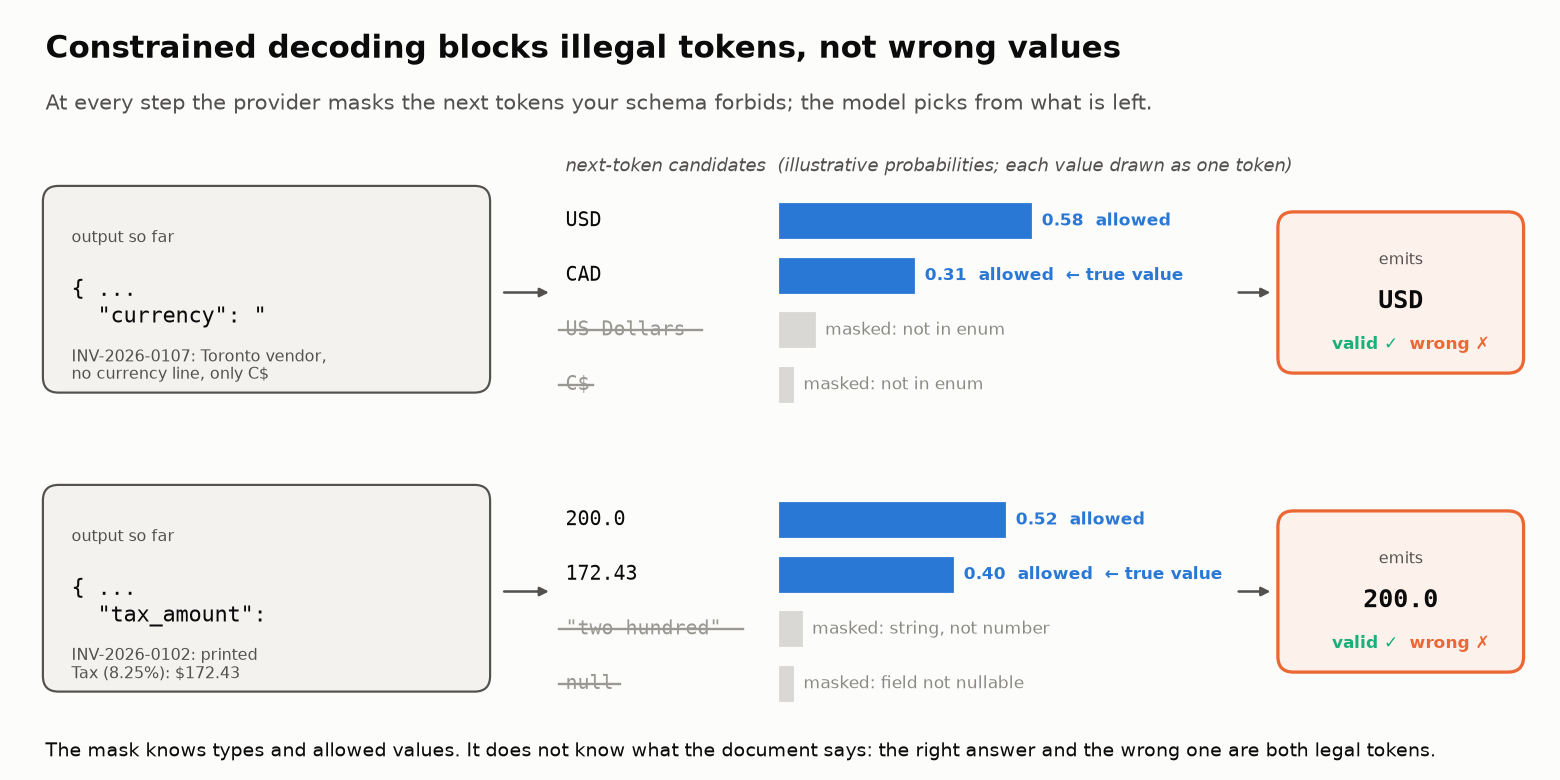

<sub>🖼️ *The mask enforces types and allowed values. `USD` and `CAD` are both legal, so the grammar cannot stop the wrong one.*</sub>

#### Steps
1. Read the `Invoice` Pydantic model. It **is** the schema: the SDK turns it into JSON Schema, and the provider constrains decoding to it. **Key order is generation order** (OpenAI documents that strict outputs follow the schema's key order), so `line_items` sits before `subtotal` and `total_amount`: the model writes the items before the sums that depend on them.
2. Note the three `Optional[...]` fields. Strict mode requires every key, so `Optional` here means **nullable**: the key is always present, its value may be `null`. Without that, the model has no legal way to say "not printed" (Task 6).
3. Read `extract_invoice()`, the live path for OpenAI's Responses API and Anthropic's Messages API (each provider's current text-generation endpoint). It doesn't run while `PROVIDER = "mock"`.
4. Run the cell and compare the document with its extraction. `GOLD` is the human-written answer key (the **gold labels**) you'll score against from Task 5.

> **🔮 Predict:** all 20 extractions came out of strict mode. What share are **fully correct** (every field right)? Write it into `MY_PREDICTIONS["fully_correct_pct"]` (Task 1).

> 📘 **Concept · Constrained decoding (strict structured outputs)**
>
> **What it is:** at every token the API masks what the schema forbids, so the output is valid JSON of the right shape by construction.
>
> **What it can't tell you:** which of the allowed values is true. `USD` and `CAD` are both legal at the currency key; `200.00` is a perfectly legal wrong tax.
>
> **Anchor:** INV-2026-0102 is 100% schema-valid and pays the wrong amount.

In [ ]:
class LineItem(BaseModel):
    model_config = ConfigDict(extra="forbid")
    description: str
    quantity: float
    unit_price: float
    line_total: float


class Invoice(BaseModel):
    """The extraction schema. Field descriptions are sent to the model as instructions."""
    model_config = ConfigDict(extra="forbid")
    invoice_number: str
    vendor_name: str = Field(description="Legal name exactly as printed")
    vendor_address: str
    invoice_date: str = Field(description="Issue date as YYYY-MM-DD")
    due_date: Optional[str] = Field(description="YYYY-MM-DD, or null if no due date is printed")
    po_number: Optional[str] = Field(description="Purchase-order number, or null if none is printed")
    currency: Literal["USD", "CAD", "GBP", "EUR"]
    line_items: list[LineItem]
    subtotal: float
    tax_rate: float = Field(description="Fraction, e.g. 0.0825 for 8.25%")
    tax_amount: float
    total_amount: float
    payment_terms: str
    notes: Optional[str] = Field(description="Free-text note printed on the invoice, or null")


EXTRACTION_INSTRUCTIONS = (
    "Extract this invoice into the schema. Copy values exactly as printed. "
    "If a field is not printed on the invoice, return null. Never infer, compute or guess a value."
)

In [ ]:
# @title 🔌 Live extraction with OpenAI / Anthropic structured outputs (hidden · 30 lines · used only when PROVIDER != 'mock')
def extract_invoice(source_text: str) -> dict:
    """Live extraction with native structured outputs. Not called while PROVIDER == 'mock'."""
    if PROVIDER == "openai":
        from openai import OpenAI
        resp = OpenAI().responses.parse(          # Responses API (recommended for new projects)
            model=OPENAI_MODEL,
            instructions=EXTRACTION_INSTRUCTIONS,
            input=source_text,
            text_format=Invoice,                  # strict structured output: constrained decoding
        )
        if resp.output_parsed is None:            # refusal or incomplete response
            raise RuntimeError("No parsed output (refusal or incomplete response)")
        return resp.output_parsed.model_dump()
    if PROVIDER == "anthropic":
        import anthropic
        resp = anthropic.Anthropic().messages.parse(
            model=ANTHROPIC_MODEL,
            max_tokens=4096,
            system=EXTRACTION_INSTRUCTIONS,
            messages=[{"role": "user", "content": source_text}],
            output_format=Invoice,                # structured outputs; no temperature (HTTP 400 since API 2026-10-21)
        )
        if resp.stop_reason != "end_turn":        # "refusal" or "max_tokens" means no trustworthy record
            raise RuntimeError(f"Extraction stopped early: stop_reason={resp.stop_reason!r}")
        return resp.parsed_output.model_dump()
    raise ValueError(f"Unknown PROVIDER {PROVIDER!r}")

In [ ]:
# 👀 Look at: in mock mode the batch is 20 recorded strict-mode extractions; the schema above is what produced them.
# --- Build the batch -------------------------------------------------------------------------
if PROVIDER == "mock":
    outputs = deepcopy(MOCK_OUTPUTS)              # recorded strict-mode responses
else:
    outputs = {iid: extract_invoice(text) for iid, text in SOURCES.items()}

FIELDS = list(Invoice.model_fields)
example_id = "INV-2026-0102"
print(f"📄 SOURCE DOCUMENT  {example_id}\n" + "─" * 66)
print(SOURCES[example_id])
print("\n🤖 EXTRACTION (abridged)\n" + "─" * 66)
shown = {k: v for k, v in outputs[example_id].items() if k not in ("line_items", "vendor_address")}
print(json.dumps(shown, indent=1))

tiles([
    ("Invoices in the batch", len(outputs), "one extraction each", None),
    ("Fields per invoice", len(FIELDS), "incl. a nested line_items list", None),
    ("Gold labels", len(GOLD), "human answer key", None),
    ("Provider", PROVIDER, "offline replay" if PROVIDER == "mock" else "live API", None),
])

In [ ]:
insight(
    "Reason free, constrain late: whether constraints cost accuracy is still open",
    "Tam et al. (*Let Me Speak Freely?*, EMNLP 2024) found format restrictions degraded reasoning; the *Say What You "
    "Mean* rebuttal (2024) blamed prompt and parsing artifacts. 2026 work finds a real but conditional cost: *The "
    "Constraint Tax* (arXiv 2605.26128) measures accuracy loss under strict schemas, worst for small models, and "
    "arXiv 2604.03616 sees reasoning degrade in open-weight models. *Thinking Before Constraining* (arXiv 2601.07525) "
    "reports gains of up to 27% from letting the model reason unconstrained (or in a leading `reasoning` field) "
    "before it emits the constrained record.\n"
    "**Rule of thumb:** copy-the-value extraction like this one: constrain directly. Anything needing arithmetic or "
    "judgement: reason first, constrain last, and measure both on your own eval set.",
    kind="research",
)

#### Checkpoint ✅
A plain-text invoice, its JSON extraction, four tiles, and a 📚 research card.

#### Expected Output
```
📄 SOURCE DOCUMENT  INV-2026-0102
──────────────────────────────────────────────────────────────────
TechParts Inc.
456 Oak Ave, Austin, TX 73301

INVOICE  INV-2026-0102
Invoice date: 2026-03-05
Due date:     2026-04-04
Terms:        Net 30
Currency:     USD
...
Subtotal:   $2,090.00
Tax (8.25%):  $172.43
TOTAL:      $2,262.43
Notes: Bulk order discount applied

🤖 EXTRACTION (abridged)
...
 "tax_amount": 200.0,
 "total_amount": 2290.0,
...
```
Tiles: **20** invoices · **14** fields · **20** gold labels · provider **mock**.

The document says the tax is **$172.43**; the extraction says **200.0**. That record is schema-valid. Hold that thought.

### Task 3: Schema validation: still necessary, no longer informative 📐

**Stakes:** Reporting schema validity as quality is how a wrong tax amount ships under a green dashboard.

#### Goal
Every output checked against an explicit **JSON Schema** (a standard JSON document declaring allowed keys, types and values) and against the Pydantic model, next to two outputs from a 2024-style prompt-only pipeline ("please answer in JSON", no constrained decoding).

#### Steps
1. Read `invoice_schema`. It mirrors the `Invoice` model: `"type": ["string", "null"]` for the nullable fields, `additionalProperties: false` (no extra keys), and every key `required`, which is what strict mode demands.
2. Run validation. `iter_errors()` collects **all** errors, not just the first.
3. Compare the strict batch with `LEGACY_OUTPUTS`.

> **🔮 Predict:** how many of the 20 strict-mode outputs fail schema validation? How many of the 2 legacy ones?

In [ ]:
DATE = r"^\d{4}-\d{2}-\d{2}$"
invoice_schema = {
    "type": "object",
    "additionalProperties": False,
    "required": FIELDS,                                   # strict modes require every key (nullable ≠ optional)
    "properties": {
        "invoice_number": {"type": "string", "pattern": r"^INV-\d{4}-\d{4}$"},
        "vendor_name": {"type": "string", "minLength": 1},
        "vendor_address": {"type": "string"},
        "invoice_date": {"type": "string", "pattern": DATE},
        "due_date": {"type": ["string", "null"], "pattern": DATE},
        "po_number": {"type": ["string", "null"]},
        "currency": {"type": "string", "enum": ["USD", "CAD", "GBP", "EUR"]},
        "line_items": {
            "type": "array", "minItems": 1,
            "items": {"type": "object", "additionalProperties": False,
                      "required": ["description", "quantity", "unit_price", "line_total"],
                      "properties": {"description": {"type": "string"},
                                     "quantity": {"type": "number", "minimum": 0},
                                     "unit_price": {"type": "number", "minimum": 0},
                                     "line_total": {"type": "number", "minimum": 0}}}},
        "subtotal": {"type": "number", "minimum": 0},
        "tax_rate": {"type": "number", "minimum": 0, "maximum": 1},
        "tax_amount": {"type": "number", "minimum": 0},
        "total_amount": {"type": "number", "minimum": 0},
        "payment_terms": {"type": "string"},
        "notes": {"type": ["string", "null"]},
    },
}
validator = jsonschema.Draft202012Validator(invoice_schema)


def schema_errors(record):
    """All schema violations for one record, as readable strings (empty list = valid)."""
    return [f"{'.'.join(map(str, e.absolute_path)) or '(root)'}: {e.message}" for e in validator.iter_errors(record)]


def pydantic_ok(record):
    try:
        Invoice.model_validate(record)
        return True
    except PydanticValidationError:
        return False

In [ ]:
# 👀 Look at: the legacy records fail on TYPES; the strict batch passes with a wrong tax inside it.
schema_results = {iid: schema_errors(rec) for iid, rec in outputs.items()}
n_valid = sum(not errs for errs in schema_results.values())
n_pyd = sum(pydantic_ok(rec) for rec in outputs.values())
legacy_results = {lid: schema_errors(rec) for lid, rec in LEGACY_OUTPUTS.items()}
n_legacy_valid = sum(not errs for errs in legacy_results.values())

print(f"Strict batch: {n_valid}/{len(outputs)} schema-valid · {n_pyd}/{len(outputs)} parse into Invoice")
for lid, errs in legacy_results.items():
    print(f"\n{lid}: {'✅ valid' if not errs else f'❌ {len(errs)} error(s)'}")
    for e in errs:
        print(f"   → {e[:90]}")

schema_rate = n_valid / len(outputs)
tiles([
    ("Strict batch: schema-valid", f"{schema_rate:.0%}", f"{n_valid}/{len(outputs)} records", "good" if schema_rate == 1 else "critical"),
    ("Strict batch: Pydantic parse", f"{n_pyd}/{len(outputs)}", "Invoice.model_validate", "good" if n_pyd == len(outputs) else "critical"),
    ("Legacy prompt-only JSON", f"{n_legacy_valid}/{len(LEGACY_OUTPUTS)}", "no constrained decoding", "critical" if n_legacy_valid < len(LEGACY_OUTPUTS) else "good"),
])

In [ ]:
insight(
    f"{schema_rate:.0%} schema-valid, and that number cannot tell a good invoice from a bad one",
    f"All {n_valid} strict-mode records pass, including INV-2026-0102 with its wrong tax. Validity is true *by "
    "construction*, so as a quality metric it carries no information. The legacy pipeline shows what the check is "
    f"still for: {len(LEGACY_OUTPUTS) - n_legacy_valid} of {len(LEGACY_OUTPUTS)} prompt-only outputs are malformed "
    "(numbers as strings, a sentence instead of a list, an invalid currency code).\n"
    "**Rule of thumb:** keep schema validation as a free pipeline-health gate that must read 100%; anything less is "
    "a bug or a provider change, not a quality signal.",
)
insight(
    "Valid JSON stopped being the hard part: the benchmarks agree",
    "\"% valid JSON\" is an outdated headline metric for API models with strict mode, but not everywhere: in "
    "**ExtractBench** (arXiv 2602.12247, 2026) only **51%** of 210 frontier-model PDF-to-JSON attempts were valid "
    "JSON at all, because complex schemas and models without grammar-constrained decoding still break. For this "
    "lab: keep the check as pipeline health, and remember the grammar enforces *types*, not sums or date order "
    "(Task 8).",
    kind="research",
)

#### Checkpoint ✅
Every strict-mode record is valid; both legacy records fail.

#### Expected Output
```
Strict batch: 20/20 schema-valid · 20/20 parse into Invoice

legacy-A: ❌ 2 error(s)
   → line_items.0.quantity: '10' is not of type 'number'
   → line_items.0.unit_price: '32.99' is not of type 'number'

legacy-B: ❌ 2 error(s)
   → currency: 'US Dollars' is not one of ['USD', 'CAD', 'GBP', 'EUR']
   → line_items: '500 business cards at $0.10 each = $50.00' is not of type 'array'
```
Tiles: **100%** schema-valid · **20/20** Pydantic · **0/2** legacy. Then a 💡 card and a 📚 card.

(The order of legacy-B's two errors can differ between `jsonschema` versions.)

### 🔍 What Just Happened?

The dashboard was right: 100% schema-valid. It was also useless: INV-2026-0102 is in that 100%. Keep the check for broken *pipelines* (the legacy outputs); stop reporting it as quality.

**Bridge:** quality lives in the values. Before scoring them, decide which wrong values hurt.

🗣️ **Say it to a colleague:** "Schema validity is a pipeline-health gate that must read 100%. The moment it does, it stops being a quality metric."

### Task 4: 🧠 Your Turn: decide what "wrong" costs ⚖️

**Stakes:** Equal weights pay the wrong vendor as calmly as they misspell a note.

#### Goal
A business-impact weight for each field, and a list of the **critical** fields: those where one error makes the whole record unusable.

#### Why
A wrong `notes` field is a nuisance; a wrong `total_amount` pays the wrong amount; a wrong `invoice_date` posts the expense and its tax to the wrong period. Counted equally, a perfect `notes` field offsets a wrong total.

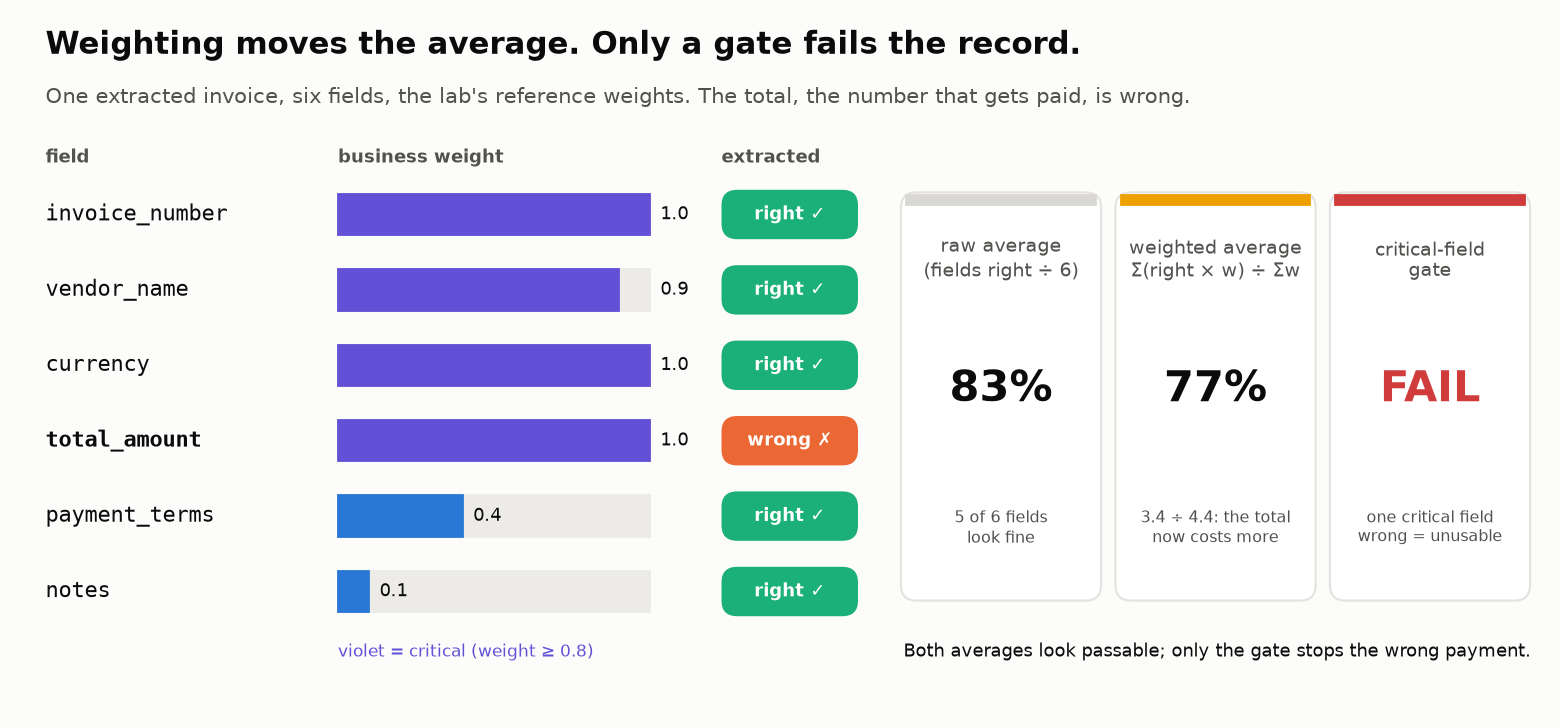

<sub>🖼️ *Weighting moves the average (83% → 77%); only the gate fails the record.*</sub>

Two tools, two jobs:

- **Weighting** changes how much a wrong field lowers the average: `weighted accuracy = Σ (correct × weight) / Σ weight`.
- **Gating** makes one wrong critical field fail the whole record, whatever the other 13 fields score. No weight can express that.

Weights are **domain decisions**, so write down why (the ✍️ cell).

#### Steps
1. Spend 2 minutes on the ✍️ cell.
2. In the code cell, replace the `0.0`s with weights from 0.0 to 1.0. Weight **≥ 0.8** makes a field **critical**.
3. Run it. If every weight is still 0.0, the cell uses the reference weights and says so.

> **🔮 Predict:** which single field, if wrong, costs an accounts-payable team the most? Does the answer change for a tax-preparation product?

### ✍️ Your Analysis

**Write your answers here** (double-click to edit):

1. **Critical fields** (an error makes the record unusable or causes financial / compliance harm):

   *Your answer...*

2. **Low-impact fields** (an error is tolerable):

   *Your answer...*

3. **Relationships that must always hold** between fields (you'll encode these in Task 8):

   *Your answer...*

4. **Would your weights change** for a different product (e.g. a tax-filing assistant, or a medical-claims form)?

   *Your answer...*

In [ ]:
# 🧠 YOUR TURN: replace each 0.0 with a weight between 0.0 (doesn't matter) and 1.0 (mission-critical).
# Ask of every field: "if THIS is wrong, what happens next?"
field_weights = {
    "invoice_number": 0.0,   # reconciliation key
    "vendor_name": 0.0,      # who gets paid
    "vendor_address": 0.0,   # correspondence
    "invoice_date": 0.0,     # accounting and tax period
    "due_date": 0.0,         # late fees, cash planning
    "po_number": 0.0,        # three-way match with purchasing
    "currency": 0.0,         # same digits, different money
    "line_items": 0.0,       # what was bought: expense coding, audit
    "subtotal": 0.0,         # pre-tax amount
    "tax_rate": 0.0,         # must match the jurisdiction
    "tax_amount": 0.0,       # flows into tax reporting
    "total_amount": 0.0,     # THE number that gets paid
    "payment_terms": 0.0,
    "notes": 0.0,
}
CRITICAL_MIN_WEIGHT = 0.8

if not any(field_weights.values()):
    print("📝 No weights set yet, so the REFERENCE weights are used. Come back and set your own.\n")
    field_weights = dict(REFERENCE_WEIGHTS)
assert set(field_weights) == set(FIELDS), "field_weights must have exactly one entry per field"
assert all(0.0 <= w <= 1.0 for w in field_weights.values()), "weights must be between 0.0 and 1.0"

CRITICAL = [f for f in FIELDS if field_weights[f] >= CRITICAL_MIN_WEIGHT]
for f, w in sorted(field_weights.items(), key=lambda kv: -kv[1]):
    print(f"  {f:15s} {w:.1f} {'█' * int(w * 20):20s} {'◀ critical' if f in CRITICAL else ''}")

crit_share = sum(field_weights[f] for f in CRITICAL) / sum(field_weights.values())
insight(
    f"{len(CRITICAL)} of {len(FIELDS)} fields are critical, and they carry {crit_share:.0%} of the weight",
    f"Critical: {', '.join(f'`{f}`' for f in CRITICAL)}. From here on a record counts as usable only if **every** "
    "critical field is right: that is the gate, and no weight can replace it.\n"
    "**Rule of thumb:** weight for the dashboard, gate on critical fields, and get the weights from the people who "
    "absorb the errors (finance, tax, support), not from the engineer writing the scorer.",
    kind="numbers",
)

#### Checkpoint ✅
A bar list of your weights with `◀ critical` markers, then a 📈 card.

#### Expected Output (with the reference weights)
```
📝 No weights set yet, so the REFERENCE weights are used. Come back and set your own.

  invoice_number  1.0 ████████████████████ ◀ critical
  currency        1.0 ████████████████████ ◀ critical
  total_amount    1.0 ████████████████████ ◀ critical
  vendor_name     0.9 ██████████████████   ◀ critical
  tax_amount      0.9 ██████████████████   ◀ critical
  invoice_date    0.8 ████████████████     ◀ critical
  line_items      0.8 ████████████████     ◀ critical
  subtotal        0.8 ████████████████     ◀ critical
  tax_rate        0.7 ██████████████
  due_date        0.6 ████████████
  po_number       0.6 ████████████
  payment_terms   0.4 ████████
  vendor_address  0.3 ██████
  notes           0.1 ██
```
Card: **8 of 14 fields are critical, and they carry 73% of the weight**. With your own weights, the numbers in Tasks 5–10 will differ a little from the Expected Output blocks.

### ✍️ Your Justification

- **Why did your top-weighted fields earn their weight?** *Your answer...*
- **Which weight would you most want a finance or tax partner to review?** *Your answer...*

**Bridge:** you know what each field is worth. Now measure how often each field is right, and how often a **whole invoice** is.

### Task 5: Field accuracy *and* record accuracy: the plot twist 🎯

**Stakes:** Field accuracy is what the model does; record accuracy is what the customer gets.

#### Goal
Every field scored against gold with a type-appropriate comparator, and the batch reported at three levels, each with its own denominator:

| Metric | Numerator ÷ denominator | In this batch |
|---|---|---|
| **Field accuracy** | correct (invoice, field) slots ÷ all slots | ÷ 20 × 14 = 280 slots |
| **Record accuracy** | invoices with *every* field right ÷ invoices | ÷ 20 |
| **Critical-record accuracy** | invoices with every *critical* field right ÷ invoices | ÷ 20 |

Weighted field accuracy (Task 4) is field accuracy with weights.

#### Comparators
A comparator decides whether a predicted value equals the gold value, so it is part of the metric: a plain `==` would count two correct records here as errors.

| Field kind | Comparator | Why |
|---|---|---|
| Money (`subtotal`, `tax_amount`, `total_amount`) | equal to the cent | $0.004 is rounding; $0.01 is a different invoice |
| `vendor_name` | **normalised exact**: casefold (Unicode-safe lowercase), strip punctuation, drop trailing legal suffixes (Inc, LLC, Ltd, Co) | "Bayside Freight Partners" and "... LLC" are the same payee; "TechParts **l**nc." (an OCR-style `l`-for-`I` swap) is not "TechParts **I**nc." |
| `line_items` | **order-insensitive**: match items by description, then compare qty / price / total | the same items in another order are not an error |
| IDs, ISO dates, currency, terms, notes | normalised exact (case and whitespace) | |
| Exactly one side `null` | **always wrong** | Task 6 looks at these |

#### Steps
1. Run the cell. It scores the 280 slots against `GOLD`.
2. Read the chart top to bottom. Whiskers are **95% confidence intervals** (CI): the range of true rates consistent with what you measured. They use the **Wilson** formula, which stays honest at small n. At n = 20 they're wide, and that width is part of the result.
3. Read the 🔎 line. `SequenceMatcher.ratio()` (Python's `difflib` similarity: 2 × matching characters ÷ total characters, from 0 to 1) is the usual fuzzy-match score.

<details><summary>📐 The Wilson interval, once (click)</summary>

For k successes in n trials, p̂ = k/n and z = 1.96 for 95%:

centre = (p̂ + z²/2n) / (1 + z²/n)  half-width = z·√(p̂(1−p̂)/n + z²/4n²) / (1 + z²/n)

**Worked:** 12 of 20 → p̂ = 0.60, centre 0.584, half-width 0.197 → **39%–78%**. The textbook p̂ ± 1.96·√(p̂(1−p̂)/n) says 20 of 20 is "100%–100%"; Wilson says **84%–100%**, which is why Task 10 can't pass on 20 invoices.

</details>

> **🔮 Predict:** you guessed a fully-correct share in Task 2. Knowing the batch is 100% schema-valid, do you raise or lower it?

> 📘 **Concept · Field accuracy vs record accuracy**
>
> **What it is:** field accuracy counts correct (invoice, field) slots over all slots; record accuracy counts invoices with *every* field right.
>
> **What it can't tell you:** field accuracy can't tell you how many invoices are usable: 94% per field over 14 fields leaves fewer than half the records whole.
>
> **Anchor:** the plot twist of Task 5: 100% valid, 94% of fields right, 8 of 20 invoices fully right.

In [ ]:
# @title 🧰 Comparators: cents, normalised vendor names, line items (hidden · 22 lines · expand if curious)
MONEY = {"subtotal", "tax_amount", "total_amount"}
LEGAL_SUFFIXES = {"inc", "llc", "ltd", "co", "corp", "plc", "gmbh"}


def norm_text(s):
    return " ".join(str(s).casefold().split())


def norm_name(s):
    words = re.sub(r"[^\w\s&]", " ", str(s).casefold()).split()
    while words and words[-1] in LEGAL_SUFFIXES:
        words.pop()
    return " ".join(words)


def same_cents(a, b):
    return abs(float(a) - float(b)) < 0.005 + 1e-9


def line_items_match(pred, gold):
    if not isinstance(pred, list) or len(pred) != len(gold):
        return False
    key = lambda li: norm_text(li["description"])
    return all(key(p) == key(g) and all(same_cents(p[k], g[k]) for k in ("quantity", "unit_price", "line_total"))
               for p, g in zip(sorted(pred, key=key), sorted(gold, key=key)))

In [ ]:
# 👀 Look at: one comparator per field type; a plain == would fail 'TechParts Inc' vs 'TechParts Inc.'
def field_correct(field, pred, gold):
    if pred is None or gold is None:
        return pred is None and gold is None
    if field in MONEY:
        return same_cents(pred, gold)
    if field == "tax_rate":
        return abs(pred - gold) < 1e-6
    if field == "line_items":
        return line_items_match(pred, gold)
    if field == "vendor_name":
        return norm_name(pred) == norm_name(gold)
    return norm_text(pred) == norm_text(gold)


def score_batch(outs, gold):
    """One row per (invoice, field) with a correct/incorrect flag."""
    return pd.DataFrame([{"invoice": iid, "field": f, "correct": field_correct(f, outs[iid].get(f), gold[iid].get(f))}
                         for iid in gold for f in FIELDS])


def summarize(scored):
    w = scored["field"].map(field_weights)
    by_inv = scored.groupby("invoice")
    crit_ok = scored[scored["field"].isin(CRITICAL)].groupby("invoice")["correct"].all()
    return {"n": scored["invoice"].nunique(),
            "field_acc": scored["correct"].mean(),
            "weighted_acc": (scored["correct"] * w).sum() / w.sum(),
            "crit_records": int(crit_ok.sum()),
            "full_records": int(by_inv["correct"].all().sum())}

In [ ]:
scored = score_batch(outputs, GOLD)
S = summarize(scored)
n = S["n"]
crit_rate, full_rate = S["crit_records"] / n, S["full_records"] / n
crit_ci, full_ci = wilson(S["crit_records"], n), wilson(S["full_records"], n)

# --- Reveal: one chart, five views of the same batch ---------------------------------------

In [ ]:
# @title 📊 The five-views chart (hidden · 20 lines · expand if curious)
labels = ["Schema-valid records", "Field accuracy", "Weighted field accuracy",
          "Critical-record accuracy\n(every critical field right)", "Record accuracy\n(every field right)"]
values = [schema_rate, S["field_acc"], S["weighted_acc"], crit_rate, full_rate]
colors = [PALETTE[0]] * 3 + [PALETTE[1]] * 2
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(labels[::-1], values[::-1], color=colors[::-1], height=0.6)
for (lo, hi), y in ((full_ci, 0), (crit_ci, 1)):
    ax.errorbar(values[::-1][y], y, xerr=[[values[::-1][y] - lo], [hi - values[::-1][y]]],
                fmt="none", ecolor="#52514e", capsize=4, lw=1.2)
label_x = {0: full_ci[1], 1: crit_ci[1]}          # print the CI bars' labels past the whisker
for y, v in enumerate(values[::-1]):
    ax.text(label_x.get(y, v) + 0.012, y, f"{v:.0%}", va="center", fontsize=11, color="#0b0b0b", weight="bold")
ax.set_xlim(0, 1.12)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_title("Value errors hide behind 100% schema validity")
ax.set_xlabel(f"n = {n} invoices × {len(FIELDS)} fields · whiskers = 95% Wilson CI on record-level rates")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [ ]:
errs = scored[~scored["correct"]].groupby("field")["invoice"].apply(lambda s: ", ".join(i[-4:] for i in s))
print("Fields with errors (invoice suffixes):")
for f, ids in errs.items():
    print(f"  {f:15s} weight {field_weights[f]:.1f}  {'◀ critical' if f in CRITICAL else '          '}  {ids}")

typo_pred, typo_gold = outputs["INV-2026-0104"]["vendor_name"], GOLD["INV-2026-0104"]["vendor_name"]
ok_pred, ok_gold = outputs["INV-2026-0116"]["vendor_name"], GOLD["INV-2026-0116"]["vendor_name"]
r_typo, r_ok = SequenceMatcher(None, typo_pred, typo_gold).ratio(), SequenceMatcher(None, ok_pred, ok_gold).ratio()
print(f"\n🔎 Fuzzy-match trap: '{typo_pred}' vs '{typo_gold}' has similarity {r_typo:.3f}; the legitimate "
      f"'{ok_pred}' vs '{ok_gold}' only {r_ok:.3f}.\n   No fuzzy threshold accepts the second and rejects the first. "
      f"Normalisation does: {field_correct('vendor_name', typo_pred, typo_gold)} / {field_correct('vendor_name', ok_pred, ok_gold)}.")

independent = S["field_acc"] ** len(FIELDS)
insight(
    f"{schema_rate:.0%} schema-valid, {S['field_acc']:.0%} of fields right, yet only "
    f"{S['full_records']} of {n} invoices are fully right",
    f"An invoice is only as good as its worst field: "
    f"{S['field_acc']:.1%} per field across {len(FIELDS)} fields compounds to "
    f"{S['field_acc']:.3f}^{len(FIELDS)} ≈ **{independent:.0%}** fully-right records if errors were independent, "
    f"next to the {full_rate:.0%} you measured. Critical-record accuracy is **{S['crit_records']}/{n} ({crit_rate:.0%}, 95% CI "
    f"{crit_ci[0]:.0%}–{crit_ci[1]:.0%})**; the rest would pay, post or report "
    f"something wrong.\n"
    "**Rule of thumb:** report record accuracy next to field accuracy, always. Record accuracy is what the "
    "customer gets; field accuracy is what the model does.",
    kind="surprise",
)
insight(
    "Schema-valid ≠ correct, in every 2025–26 structured-output benchmark",
    "**Structured Output Benchmark** (SOB, arXiv 2604.25359, 2026): JSON pass rates often above 95%, while value "
    "accuracy trails by **15–25 points**; hallucinated values \"often appear plausible and structurally correct\". "
    "**ExtractBench** (arXiv 2602.12247, 2026): 65–80% field accuracy when the JSON was valid, but only a **4.6%** "
    "pass rate with every field correct. **SO-Bench** (arXiv 2511.21750, 2025): GPT-5 and Gemini 2.5 Pro follow "
    "schemas over 95% of the time, yet at most **17.1%** of outputs are fully correct. **Cleanlab** recommends "
    "reporting both *Field Accuracy* and *Output Accuracy* (a record is wrong if any field is wrong). The gap you "
    "just measured has the same shape.",
    kind="research",
)

#### Checkpoint ✅
One bar chart titled **"Value errors hide behind 100% schema validity"**, a list of fields with errors, a 🔎 fuzzy-match line, and two cards.

#### Expected Output (reference weights)
Chart bars, top to bottom: **100%** schema-valid · **94%** field accuracy · **93%** weighted · **60%** critical-record accuracy · **40%** record accuracy.
```
Fields with errors (invoice suffixes):
  currency        weight 1.0  ◀ critical  0107
  due_date        weight 0.6              0103, 0106, 0119
  invoice_date    weight 0.8  ◀ critical  0106
  line_items      weight 0.8  ◀ critical  0105, 0117
  po_number       weight 0.6              0109, 0110
  subtotal        weight 0.8  ◀ critical  0105
  tax_amount      weight 0.9  ◀ critical  0102, 0105
  total_amount    weight 1.0  ◀ critical  0102, 0105, 0112, 0118
  vendor_name     weight 0.9  ◀ critical  0104

🔎 Fuzzy-match trap: 'TechParts lnc.' vs 'TechParts Inc.' has similarity 0.929; the legitimate 'Bayside Freight Partners' vs 'Bayside Freight Partners LLC' only 0.923.
   No fuzzy threshold accepts the second and rejects the first. Normalisation does: False / True.
```
Cards: 🤯 **100% schema-valid, 94% of fields right, yet only 8 of 20 invoices are fully right** (0.939^14 ≈ 42% predicted vs 40% measured; critical-record accuracy **12/20, 60%, 95% CI 39%–78%**), then a 📚 card with the benchmark numbers.

Two correct records the comparators *accepted*: INV-2026-0115 lists its items in another order and INV-2026-0116 drops "LLC". Neither is in the error list.

### 🔍 What Just Happened?

The **plot twist**: 100% schema-valid, 94% field-accurate, and fewer than half the invoices fully right. Errors compound across fields, so record accuracy is the number to put in front of the business.

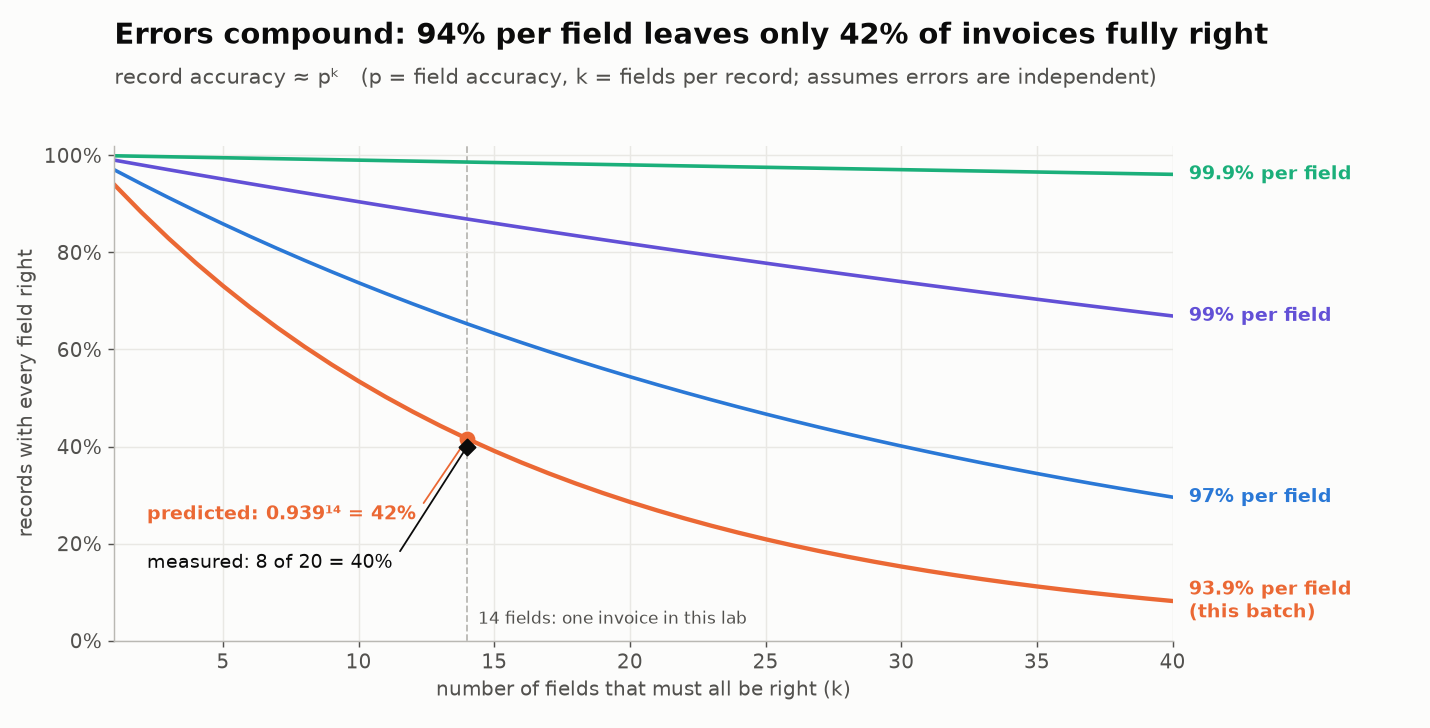

<sub>🖼️ *Record accuracy ≈ pᵏ. Each extra field is another chance to be wrong.*</sub>

Run the formula on your own forms: **99% per field still leaves 13% of 14-field invoices wrong somewhere**, and a 50-field form needs **99.9% per field** to come out fully right 95% of the time (0.999⁵⁰ ≈ 0.95).

**Bridge:** `due_date` and `po_number` appear in the error list several times. Some of those aren't wrong values; they are values for things the document never printed. That failure needs its own metric.

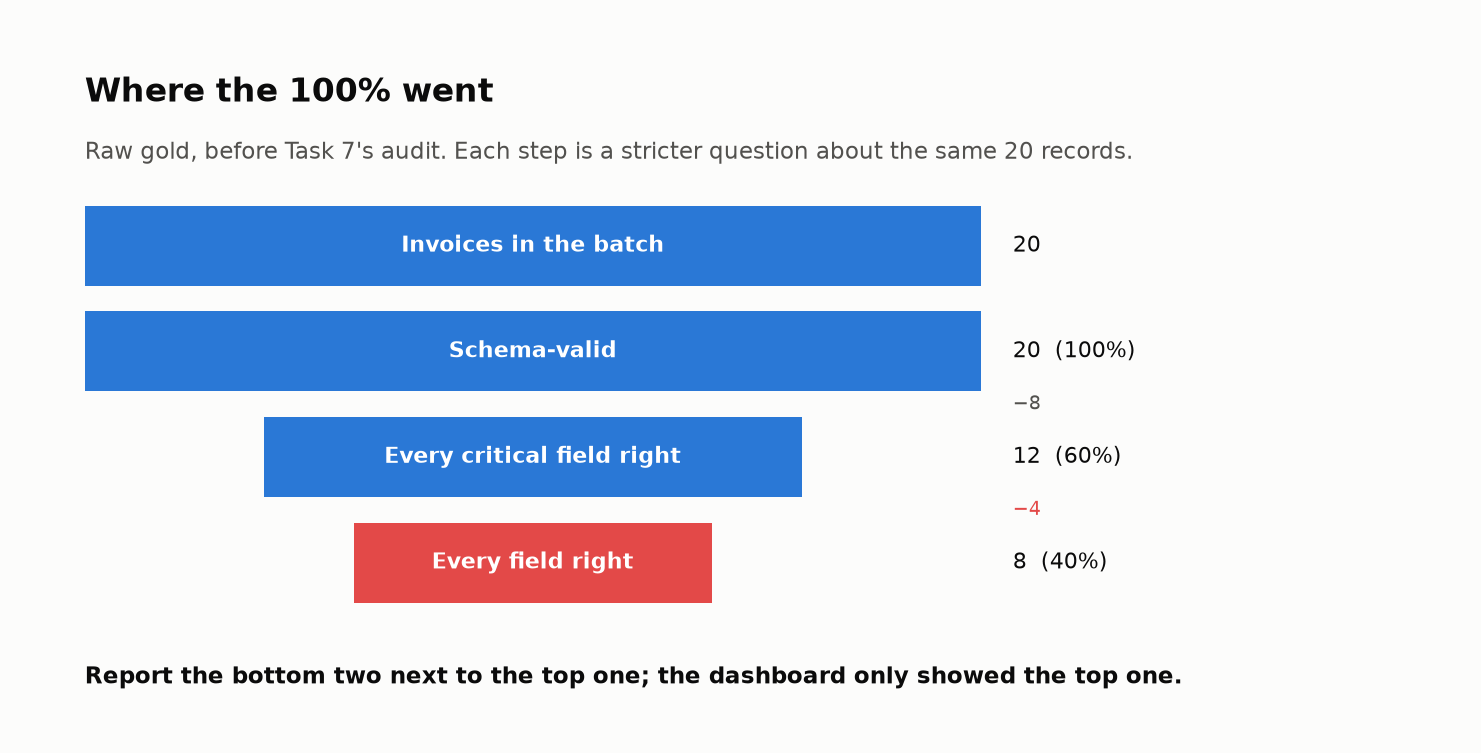
<sub>🖼️ *Four questions about the same 20 records; only the first one was on the dashboard.*</sub>

🗣️ **Say it to a colleague:** "Field accuracy is what the model does. Record accuracy is what the customer gets. Report both, gate on the second."

### Task 6: Null handling: abstain, hallucinate or omit? 🕳️

**Stakes:** An invented due date pays early; an invented PO number passes a three-way match.

#### Goal
The three fields that may be empty (`due_date`, `po_number`, `notes`) sorted by outcome, with the origin of each invented value. An empty field returned as `null` is a **correct abstention**; an empty field returned with a value is a **hallucinated value**; a printed value returned as `null` is an **omission**.

Two rates, two denominators:

- **Hallucination rate** = hallucinated values ÷ fields the source leaves empty (25 of the 60 nullable slots here).
- **Omission rate** = omissions ÷ fields the source prints (the other 35).

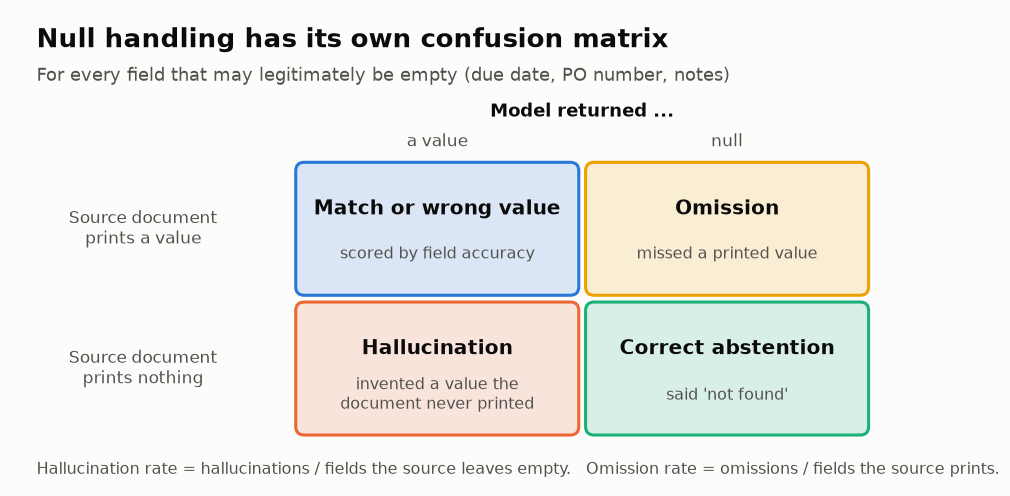

<sub>🖼️ *Null handling has its own confusion matrix.*</sub>

#### Why
A hallucinated due date schedules a payment nobody agreed to (*Net 30* means "pay within 30 days of the invoice date"; *Due on receipt* means "pay now", so no due date is printed); an invented PO number can make an invoice *pass* a three-way match it should fail. Accuracy on printed values sees neither.

#### Steps
1. Run the cell to count the outcomes.
2. Read the provenance column: where did each invented value come from?
3. See what happens to the *correct answers* under a schema that makes these fields non-nullable.

> **🔮 Predict:** of the empty fields in this batch, what share did the model fill in anyway (`hallucination_pct`)? And where would a model "find" a PO number that isn't on the page?

> 📘 **Concept · Hallucination vs omission**
>
> **What it is:** on a field the source leaves empty, a returned value is a *hallucination*; on a field the source prints, a returned `null` is an *omission*.
>
> **What it can't tell you:** a single accuracy number: it lets a model trade one for the other unnoticed, so report the two rates separately.
>
> **Anchor:** a due date computed from 'Due on receipt' and a PO number copied from the neighbouring invoice: both well-typed, both invented.

In [ ]:
NULLABLE = ["due_date", "po_number", "notes"]


def null_outcome(pred, gold):
    if gold is None:
        return "✅ correct abstention" if pred is None else "🚨 hallucinated value"
    return "🕳️ omission" if pred is None else "value vs value"


def provenance(iid, value):
    """Where could an invented value have come from?"""
    if value in SOURCES[iid]:
        return "printed in THIS invoice's own source 🤔"
    elsewhere = [j for j in SOURCES if j != iid and value in SOURCES[j]]
    if elsewhere:
        return f"copied from {elsewhere[0]}'s document"
    try:
        days = (date.fromisoformat(value) - date.fromisoformat(outputs[iid]["invoice_date"])).days
        return f"computed: invoice_date + {days} days (terms say {outputs[iid]['payment_terms']!r})"
    except ValueError:
        return "found nowhere"


def null_report(outs, gold):
    rows = [{"invoice": iid, "field": f, "pred": outs[iid][f], "gold": gold[iid][f],
             "outcome": null_outcome(outs[iid][f], gold[iid][f])} for iid in gold for f in NULLABLE]
    return pd.DataFrame(rows)

In [ ]:
nulls = null_report(outputs, GOLD)
counts = nulls["outcome"].value_counts()
gold_empty = int((nulls["gold"].isna()).sum())
gold_present = len(nulls) - gold_empty
n_hall, n_omit = int(counts.get("🚨 hallucinated value", 0)), int(counts.get("🕳️ omission", 0))
hall_rate, omit_rate = n_hall / gold_empty, n_omit / gold_present

problems = nulls[nulls["outcome"].isin(["🚨 hallucinated value", "🕳️ omission"])].copy()
problems["where the value came from"] = [provenance(r.invoice, r.pred) if isinstance(r.pred, str)
                                         else "(model returned null)" for r in problems.itertuples()]
display(problems[["invoice", "field", "pred", "gold", "outcome", "where the value came from"]]
        .astype(object).fillna("null").reset_index(drop=True))

# A schema in which "not printed" is NOT representable (the v1 many teams start with)
schema_v1 = deepcopy(invoice_schema)
for f in ("due_date", "po_number"):
    schema_v1["properties"][f]["type"] = "string"
v1 = jsonschema.Draft202012Validator(schema_v1)
unrepresentable = [iid for iid, g in GOLD.items() if not v1.is_valid(g)]

tiles([
    ("Empty fields in the source", gold_empty, f"of {len(nulls)} nullable slots", None),
    ("Correct abstentions", int(counts.get("✅ correct abstention", 0)), "said null when nothing was printed", "good"),
    ("Hallucination rate", f"{hall_rate:.0%}", f"{n_hall}/{gold_empty} empty fields filled in", "critical" if n_hall else "good"),
    ("Omission rate", f"{omit_rate:.0%}", f"{n_omit}/{gold_present} printed values missed", "warning" if n_omit else "good"),
])

In [ ]:
insight(
    f"The model invented {n_hall} values for {gold_empty} empty fields ({hall_rate:.0%}), and each invention looks real",
    "One due date was *computed* from the invoice date although the terms say 'Due on receipt'; one PO number "
    "was *copied from another invoice in the batch*. Both are well-typed and plausible, and pass every schema "
    "check. The third \"hallucination\" is printed in its own source document: remember it for Task 7.\n"
    "**Rule of thumb:** report hallucination rate (on empty fields) and omission rate (on printed fields) as two "
    "numbers; one accuracy figure lets a model trade one for the other unnoticed.",
    kind="insight",
)
insight(
    f"With a non-nullable schema, the correct answer is unrepresentable for {len(unrepresentable)} of {len(GOLD)} invoices",
    f"Validate the *gold labels* against a v1 schema where `due_date` and `po_number` are plain strings: "
    f"{len(unrepresentable)} correct records fail ({', '.join(i[-4:] for i in unrepresentable)}). Constrained "
    "decoding only emits what the grammar allows, so for those invoices a fabricated value is the *only* legal "
    "output. That is a mechanism, not a measured effect: no study has put a number on it yet, so test your own "
    "schema.\n"
    "**Rule of thumb:** every field that can be absent must be nullable (or carry an explicit `\"NOT_FOUND\"` "
    "value), and absent values belong in your eval set.",
    kind="warning",
)

#### 🎲 Watch the grammar force an invention (a toy decoder)

No model here: just made-up preferences for INV-2026-0114's `due_date` (terms *Due on receipt*, so nothing is printed) and the masking rule from Task 2. Constrained decoding drops the tokens the schema forbids and **renormalises** the rest (rescales them to sum to 1), then picks the most likely.

In [ ]:
TOY_PREFS = {"null": 0.62, "2026-04-18": 0.24, "2026-03-19": 0.10, "2026-05-03": 0.04}  # illustrative


def masked(prefs, allowed):
    kept = {tok: p for tok, p in prefs.items() if allowed(tok)}
    return {tok: p / sum(kept.values()) for tok, p in kept.items()}


views = {"nullable  (type: [string, null])": masked(TOY_PREFS, lambda t: True),
         "non-nullable  (type: string)": masked(TOY_PREFS, lambda t: t != "null")}
fig, axes = plt.subplots(1, 2, figsize=(10, 2.8), sharey=True)
for ax, (name, dist) in zip(axes, views.items()):
    pick = max(dist, key=dist.get)
    toks = list(TOY_PREFS)
    ax.barh(toks[::-1], [dist.get(t, 0) for t in toks[::-1]],
            color=[(PALETTE[2] if t == "null" else PALETTE[1]) if t == pick else "#c9c8c3" for t in toks[::-1]])
    for t in toks:
        ax.text(dist.get(t, 0) + 0.02, toks[::-1].index(t), "masked" if t not in dist else f"{dist[t]:.2f}",
                va="center", fontsize=10, color="#52514e")
    ax.set_xlim(0, 1.05); ax.set_title(name, fontsize=11, loc="left"); ax.grid(axis="y", visible=False)
    ax.set_xlabel(f"emits {pick!r}")
fig.suptitle("Remove null from the grammar and the same preferences must invent a due date", x=0.01, ha="left",
             fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()
forced = views["non-nullable  (type: string)"]
print(f"Nullable: emits null (p = {TOY_PREFS['null']:.2f}).\nNon-nullable: null is masked, so it emits "
      f"{max(forced, key=forced.get)!r} (p = {max(forced.values()):.2f} after renormalising), a Net 30 date by habit.")


#### Checkpoint ✅
A table of 4 problem slots with a provenance column, four tiles, two cards, then the 🎲 toy-decoder chart.

#### Expected Output
| invoice | field | pred | gold | outcome | where the value came from |
|---|---|---|---|---|---|
| INV-2026-0103 | due_date | 2026-04-08 | null | 🚨 hallucinated value | computed: invoice_date + 30 days (terms say 'Due on receipt') |
| INV-2026-0109 | po_number | null | PO-48213 | 🕳️ omission | (model returned null) |
| INV-2026-0110 | po_number | PO-48213 | null | 🚨 hallucinated value | copied from INV-2026-0109's document |
| INV-2026-0119 | due_date | 2026-05-10 | null | 🚨 hallucinated value | printed in THIS invoice's own source 🤔 |

Tiles: **25** empty fields · **22** correct abstentions · **12%** hallucination rate (3/25) · **3%** omission rate (1/35).
Cards: **The model invented 3 values for 25 empty fields (12%)** and **With a non-nullable schema, the correct answer is unrepresentable for 8 of 20 invoices**.

🎲 Toy decoder, titled **"Remove null from the grammar and the same preferences must invent a due date"**:
```
Nullable: emits null (p = 0.62).
Non-nullable: null is masked, so it emits '2026-04-18' (p = 0.63 after renormalising), a Net 30 date by habit.
```

### 🔍 What Just Happened?

You split "wrong" into kinds with different fixes. A computed due date is an **instruction** problem (the prompt said never compute). A PO number copied from a neighbouring document is **context contamination**, and a three-way match would accept it. A non-nullable schema would have made both worse by construction.

**Bridge:** one "hallucination", INV-2026-0119's due date, is *printed in its own source*. If the model read it right, the answer key is wrong. How many of your "model errors" are label errors?

🗣️ **Say it to a colleague:** "Absence is a value. If 'not found' isn't representable, the model's only legal output is an invention."

### Task 7: Audit the gold: is it the model, or the label? 🏷️

**Stakes:** Every metric so far trusted the answer key, and two of its labels are wrong.

#### Goal
Every model-vs-gold disagreement classified as a model error, a **label error** (the gold disagrees with the source document) or ambiguous, and the batch re-scored against the corrected answer key.

#### How `supported()` works
It looks for a value *as it would be printed* in the source: money as `1,846.80`, dates in ISO, US or day-first form, currency as its code or symbol (`CAD` / `C$`), line items as `qty x price ... total`. A `null` is supported only when the document has no such field at all.

| Model value supported? | Gold value supported? | Verdict |
|---|---|---|
| no | yes | 🤖 **model error** |
| yes | no | 🏷️ **label error**: fix the gold |
| both, or neither | | 🧑‍⚖️ **ambiguous**: send to a human |

#### Steps
1. Run the audit.
2. Read the 🧑‍⚖️ rows: why can't the text alone settle them? (Think **locale**: which country's date order?)
3. Compare the metrics before and after correcting the gold.

> **🔮 Predict:** of all the disagreements, how many are the labeller's fault (`label_errors`)?

> 📘 **Concept · Label error**
>
> **What it is:** a gold value that the source document itself contradicts; the model is right and the answer key is wrong.
>
> **What it can't tell you:** it can't be found by comparing model and gold; only the source can arbitrate, so every disagreement needs a third witness.
>
> **Anchor:** INV-2026-0118's gold total has two transposed digits; the model read the page correctly and was scored as an error.

In [ ]:
# @title 🧰 Regexes for money and line items as printed on the page (hidden · 14 lines · expand if curious)
CURRENCY_MARKERS = {"USD": ["USD", "US$"], "CAD": ["CAD", "C$"], "GBP": ["GBP", "£"], "EUR": ["EUR", "€"]}
FIELD_LABELS = {"due_date": "Due date:", "po_number": "PO number:", "notes": "Notes:"}


def _printed(number):
    """Regex for a money value as printed on the invoice (e.g. 1,846.80), not part of a longer number."""
    return r"(?<![\d.,])" + re.escape(f"{number:,.2f}") + r"(?!\d)"


def _item_printed(li):
    """Regex for one line item as printed: '<qty> x <symbol><unit price>  <symbol><line total>'."""
    sym = r"[^\d\s]*"   # an optional currency symbol such as $, C$ or £
    return (r"(?<![\d.])" + re.escape(f"{li['quantity']:g}") + r" x\s+" + sym + re.escape(f"{li['unit_price']:,.2f}")
            + r"\s+" + sym + re.escape(f"{li['line_total']:,.2f}") + r"(?!\d)")

In [ ]:
def supported(field, value, text):
    """Does the source document literally support this value?"""
    if value is None:
        return field in FIELD_LABELS and FIELD_LABELS[field] not in text
    if field in MONEY:
        return re.search(_printed(value), text) is not None
    if field == "tax_rate":
        return f"({value * 100:g}%)" in text
    if field in ("invoice_date", "due_date"):
        d = date.fromisoformat(value)
        return any(form in text for form in (value, d.strftime("%m/%d/%Y"), d.strftime("%d/%m/%Y")))
    if field == "currency":
        return any(marker in text for marker in CURRENCY_MARKERS.get(value, [value]))
    if field == "line_items":
        return all(re.search(_item_printed(li), text) for li in value)
    return norm_text(value) in norm_text(text)


def classify(pred_ok, gold_ok):
    if pred_ok and not gold_ok:
        return "🏷️ label error"
    if gold_ok and not pred_ok:
        return "🤖 model error"
    return "🧑‍⚖️ ambiguous → human"


print("🔎 Audit tools ready: supported(), classify()")


#### 🕵️ You're the auditor

Before the code audits all 17 disagreements, you audit five. Each card shows the model's value, the gold value, and the lines of the source document that matter. Pick a verdict per case (dropdowns, or edit `MY_VERDICTS`), then press **Lock in & score**. The audit cell below also scores you, so *Run All* works.

> 🎛️ **Try it:** look for the case where *both* values are on the page.

In [ ]:
# @title 🕵️ You're the auditor: five disagreements, your verdicts (run me, then play)
AUDIT_GAME = [  # (invoice, field, the source lines worth reading)
    ("INV-2026-0107", "currency", ["Maple Leaf", "Toronto", "Currency:", "TOTAL:"]),
    ("INV-2026-0118", "total_amount", ["Subtotal:", "Tax (", "TOTAL:"]),
    ("INV-2026-0106", "invoice_date", ["Brightline", "London", "Invoice date:", "Due date:"]),
    ("INV-2026-0110", "po_number", ["Quick Print", "Portland", "PO number:", "Terms:"]),
    ("INV-2026-0119", "due_date", ["Fernwood", "Invoice date:", "Due date:", "Terms:"]),
]
VERDICTS = ["🤖 model error", "🏷️ label error", "🧑‍⚖️ ambiguous → human"]
MY_VERDICTS = {iid: "🤖 model error" for iid, _, _ in AUDIT_GAME}   # ✍️ default: "the model is always wrong"
WHY = {
    "INV-2026-0107": "Toronto address, C$ amounts, and \"USD\" appears nowhere on the page. Model error: an identity "
                     "error no arithmetic rule can see.",
    "INV-2026-0118": "TOTAL on the page is 1,846.80, the model's value; the labeller transposed two digits. Label error.",
    "INV-2026-0106": "04/03/2026 fits both readings. The London address says day-first, so a human sides with the gold, "
                     "but the text alone can't prove it: route it to a person or a locale rule.",
    "INV-2026-0110": "No PO line on this page; PO-48213 is printed on INV-2026-0109. Model error: a value copied from a "
                     "neighbouring document.",
    "INV-2026-0119": "The page prints \"Due date: 2026-05-10\", exactly the model's value; the labeller missed it. "
                     "Label error.",
}


def _excerpt(iid, keys):
    lines = SOURCES[iid].splitlines()
    shown = [ln for ln in lines if any(k in ln for k in keys)]
    absent = [k for k in keys if k.endswith(":") and not any(k in ln for ln in lines)]
    return shown + [f"   (no '{k}' line on this invoice)" for k in absent]


def _fmt(v):
    return "null" if v is None else f"{v:,.2f}" if isinstance(v, float) else str(v)


def score_audit(verdicts):
    rows = []
    for k, (iid, field, _) in enumerate(AUDIT_GAME, 1):
        pred, gold, text = outputs[iid][field], GOLD[iid][field], SOURCES[iid]
        truth = classify(supported(field, pred, text), supported(field, gold, text))
        mine = verdicts[iid]
        ok = mine == truth or (truth.startswith("🧑") and mine.startswith("🤖"))  # 0106: locale knowledge counts
        rows.append((k, iid, field, mine, truth, ok))
    return rows


def show_audit_score(verdicts):
    rows = score_audit(verdicts)
    right = sum(r[5] for r in rows)
    body = "".join(
        f"<tr style='border-top:1px solid #e4e3df;vertical-align:top'><td>{'✅' if ok else '❌'}</td>"
        f"<td style='white-space:nowrap;padding-right:10px'>{k}. {iid[-4:]} <code>{f}</code></td>"
        f"<td style='white-space:nowrap;padding-right:10px'>{mine}</td>"
        f"<td style='white-space:nowrap;padding-right:10px'><b>{truth}</b></td><td style='color:#52514e'>{_html.escape(WHY[iid])}</td></tr>"
        for k, iid, f, mine, truth, ok in rows)
    _show(f"<div style='font-family:system-ui,-apple-system,sans-serif;max-width:900px;color:#0b0b0b'>"
          f"<div style='font-size:18px;font-weight:700;margin:6px 0'>🕵️ Your audit: {right} of {len(rows)} right</div>"
          f"<table style='border-collapse:collapse;font-size:13px;line-height:1.4'><tr style='text-align:left'><th></th>"
          f"<th>case</th><th>you</th><th>the audit</th><th>why</th></tr>{body}</table></div>")
    return right


cards = []
for k, (iid, field, keys) in enumerate(AUDIT_GAME, 1):
    page = _html.escape("\n".join(_excerpt(iid, keys)))
    cards.append(
        f"<div style='flex:1 1 400px;border:1px solid #e4e3df;border-top:4px solid #6250d6;border-radius:8px;"
        f"padding:10px 14px;background:#fcfcfb'>"
        f"<div style='font-weight:700'>Case {k} · {iid} · <code>{field}</code></div>"
        f"<div style='margin:8px 0;font-size:13px'>"
        f"<span style='background:#f1effc;padding:2px 8px;border-radius:10px'>🤖 model: <b>{_fmt(outputs[iid][field])}</b></span> "
        f"<span style='background:#fdf6e6;padding:2px 8px;border-radius:10px'>🏷️ gold: <b>{_fmt(GOLD[iid][field])}</b></span></div>"
        f"<pre style='background:#f3f2ef;padding:8px;border-radius:6px;font-size:12px;margin:0;white-space:pre-wrap'>{page}</pre></div>")
_show("<div style='display:flex;flex-wrap:wrap;gap:10px;max-width:900px;font-family:system-ui,-apple-system,sans-serif;"
      "color:#0b0b0b'>" + "".join(cards) + "</div>")

_dd = {}
try:
    import ipywidgets as W
    _dd = {iid: W.Dropdown(options=VERDICTS, value=MY_VERDICTS[iid], description=f"Case {k}",
                           layout=W.Layout(width="340px")) for k, (iid, _, _) in enumerate(AUDIT_GAME, 1)}
    _btn, _res = W.Button(description="Lock in & score", button_style="primary"), W.Output()

    def _on_click(_):
        with _res:
            _res.clear_output()
            show_audit_score(auditor_verdicts())

    _btn.on_click(_on_click)
    display(W.VBox(list(_dd.values()) + [_btn, _res]))
except ImportError:
    print("ipywidgets not available: edit MY_VERDICTS above, then run the audit cell below.")


def auditor_verdicts():
    """Your verdicts: the dropdowns if they exist, otherwise MY_VERDICTS."""
    return {iid: (_dd[iid].value if iid in _dd else MY_VERDICTS[iid]) for iid, _, _ in AUDIT_GAME}


In [ ]:
audit_score = show_audit_score(auditor_verdicts())   # 🕵️ your verdicts, scored against the audit below

audit = []
for row in scored[~scored["correct"]].itertuples():
    pred, gold = outputs[row.invoice][row.field], GOLD[row.invoice][row.field]
    p_ok, g_ok = supported(row.field, pred, SOURCES[row.invoice]), supported(row.field, gold, SOURCES[row.invoice])
    short = lambda v: (f"[{len(v)} items]" if isinstance(v, list) else v)
    audit.append({"invoice": row.invoice, "field": row.field, "model": short(pred), "gold": short(gold),
                  "model in source": p_ok, "gold in source": g_ok, "verdict": classify(p_ok, g_ok)})
audit = pd.DataFrame(audit)
display(audit)

# Correct the answer key where the source clearly sides with the model.
GOLD_FIXED = deepcopy(GOLD)
for r in audit[audit["verdict"] == "🏷️ label error"].itertuples():
    GOLD_FIXED[r.invoice][r.field] = deepcopy(outputs[r.invoice][r.field])

scored_fixed = score_batch(outputs, GOLD_FIXED)
S2 = summarize(scored_fixed)
nulls_fixed = null_report(outputs, GOLD_FIXED)
gold_empty2 = int(nulls_fixed["gold"].isna().sum())
n_hall2 = int((nulls_fixed["outcome"] == "🚨 hallucinated value").sum())
hall_rate2 = n_hall2 / gold_empty2
v = audit["verdict"].value_counts()
n_label, n_model, n_amb = (int(v.get(k, 0)) for k in ("🏷️ label error", "🤖 model error", "🧑‍⚖️ ambiguous → human"))

In [ ]:
tiles([
    ("Disagreements audited", len(audit), "model ≠ gold", None),
    ("🤖 Model errors", n_model, "source backs the gold", "serious"),
    ("🏷️ Label errors", n_label, "source backs the model", "warning" if n_label else "good"),
    ("🧑‍⚖️ Ambiguous", n_amb, "text alone can't decide", "warning" if n_amb else "good"),
])
tiles([
    ("Record accuracy", f"{S['full_records'] / n:.0%} → {S2['full_records'] / n:.0%}", "raw gold → corrected gold", None),
    ("Critical-record accuracy", f"{S['crit_records'] / n:.0%} → {S2['crit_records'] / n:.0%}", "raw → corrected", None),
    ("Hallucination rate", f"{hall_rate:.0%} → {hall_rate2:.0%}", f"{n_hall2}/{gold_empty2} after the fix", None),
])
insight(
    f"{n_label} of {len(audit)} \"model errors\" were the answer key's fault",
    f"INV-2026-0118's gold total has two transposed digits; INV-2026-0119's labeller missed a printed due date "
    f"(Task 6's third \"hallucination\"). Fixing both moves record accuracy from {S['full_records'] / n:.0%} to "
    f"{S2['full_records'] / n:.0%} and the hallucination rate from {hall_rate:.0%} to {hall_rate2:.0%}. The "
    f"{n_amb} ambiguous rows are INV-2026-0106's dates: `04/03/2026` is 4 March in London and April 3 in Austin, the "
    "text supports both, and only the vendor's UK address settles it, so a human or a locale rule must.\n"
    "**Rule of thumb:** check the source before blaming the model, budget for re-labelling, and treat \"model beats "
    "gold\" as a finding. Cleanlab found erroneous or inconsistent ground truth in **every** public "
    "structured-output benchmark it examined.",
    kind="surprise",
)

#### Checkpoint ✅
Your 🕵️ scorecard (5 rows), an audit table with 17 rows, two rows of tiles, and a 🤯 card.

#### Expected Output
With the default verdicts (all "🤖 model error"): **`🕵️ Your audit: 3 of 5 right`**. The two label errors (0118, 0119) are what the default misses; 0106 counts as right whether you call it ambiguous or, using the London address, a model error.

Audit verdicts: **13** 🤖 model errors · **2** 🏷️ label errors (INV-2026-0118 `total_amount`, INV-2026-0119 `due_date`) · **2** 🧑‍⚖️ ambiguous (INV-2026-0106 `invoice_date` and `due_date`).

| Metric | raw gold → corrected gold |
|---|---|
| Record accuracy | 40% → 50% |
| Critical-record accuracy | 60% → 65% |
| Hallucination rate | 12% → 8% (2/24) |

Card: **2 of 17 "model errors" were the answer key's fault**.

### 🔍 What Just Happened?

You audited the ruler before trusting the measurement: two "model errors" were label errors, and two more can't be settled from text alone. From here on every metric uses `GOLD_FIXED`.

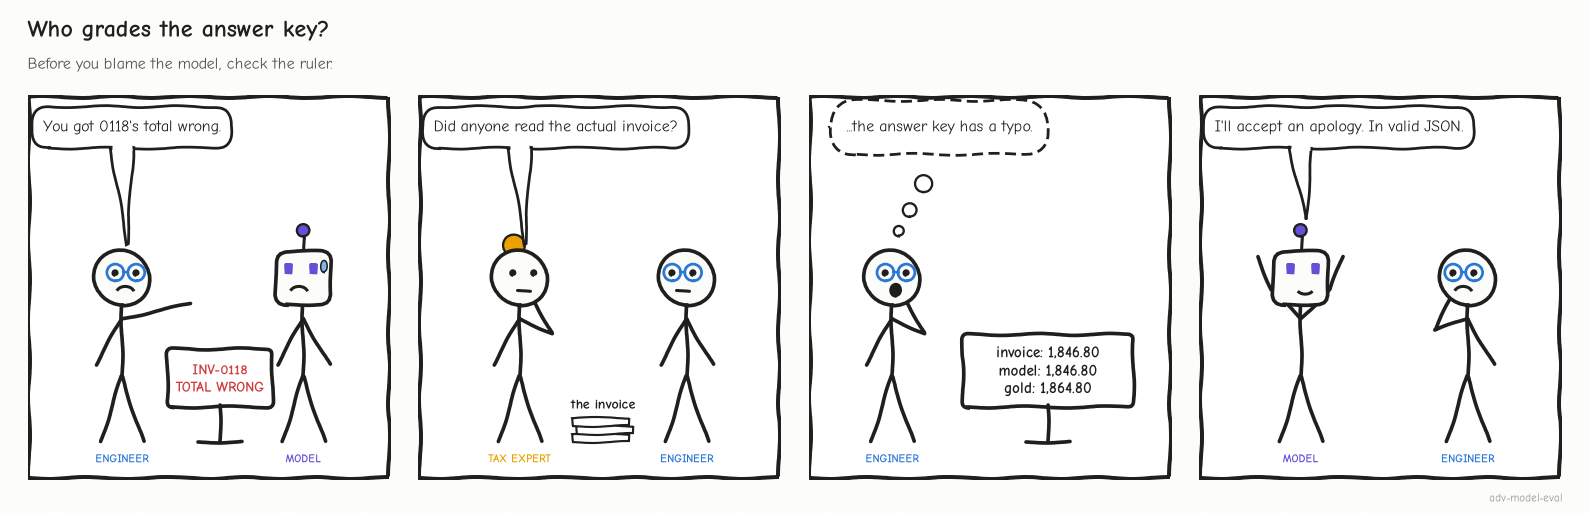

<sub>🖼️ *Who grades the answer key? Check the source before you blame the model.*</sub>

> 🏭 **In production:** audit every disagreement in the sample, not just the surprising ones. A wrong gold label does double damage: it hides real model errors and invents fake ones, and both mislead the release decision.

**Bridge:** every check so far needed a gold label, and you will only ever label a sample. Which errors could you catch on **every** invoice, with no answer key?

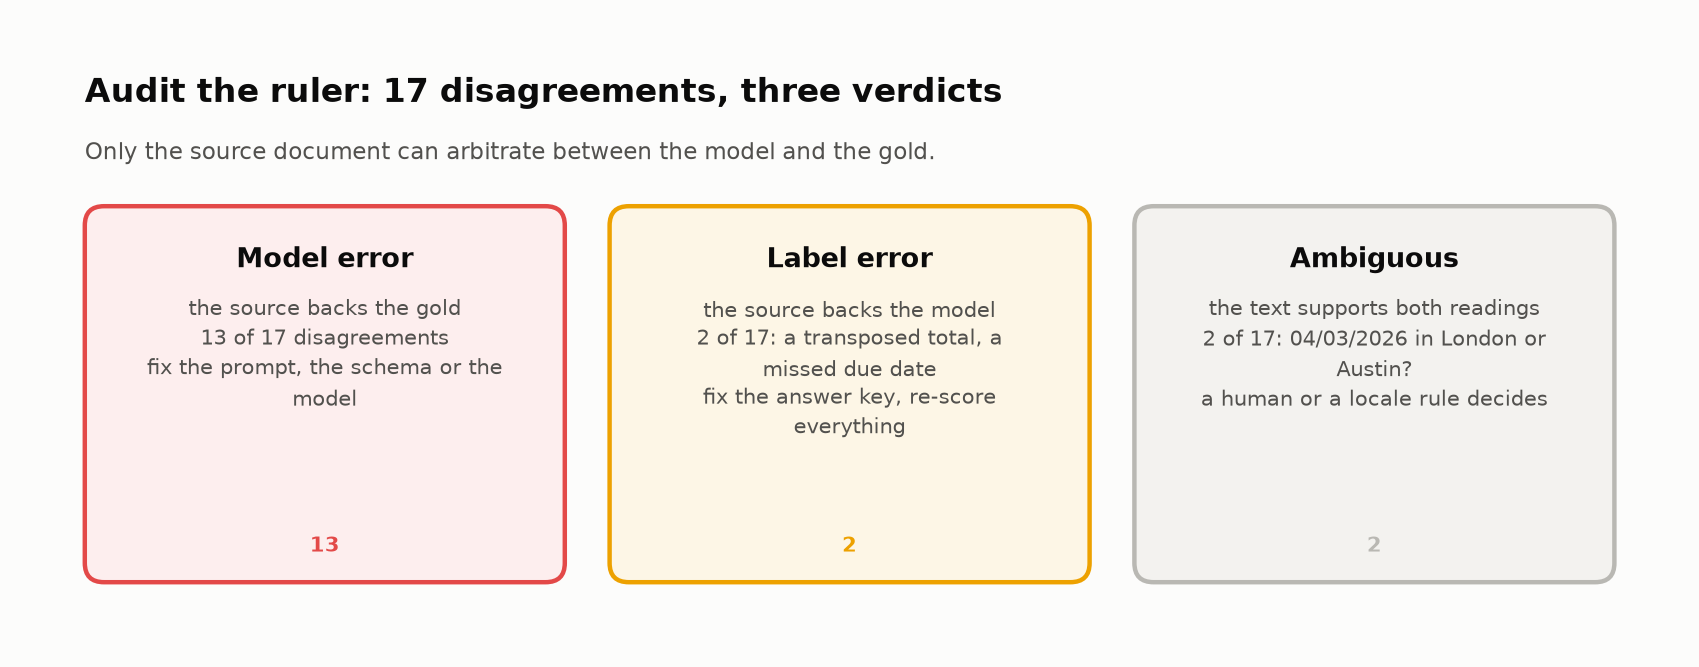
<sub>🖼️ *The source document is the third witness in every disagreement.*</sub>

🗣️ **Say it to a colleague:** "Audit the ruler before the measurement. When the model beats the gold, fix the gold and re-score everything."

🧭 **Where you are:** Act 2 of 3 (Tasks 8–9): checks that need no labels and run on every invoice.

### Task 8: 🧠 Your Turn: business rules as Pydantic validators 🔗

**Stakes:** This is the one check that runs on every invoice in production, with no labels.

#### Goal
A validator for the **business rules** (cross-field consistency checks: relationships that hold on every valid invoice), run on **all** outputs without gold, and a count of the broken invoices it catches and misses.

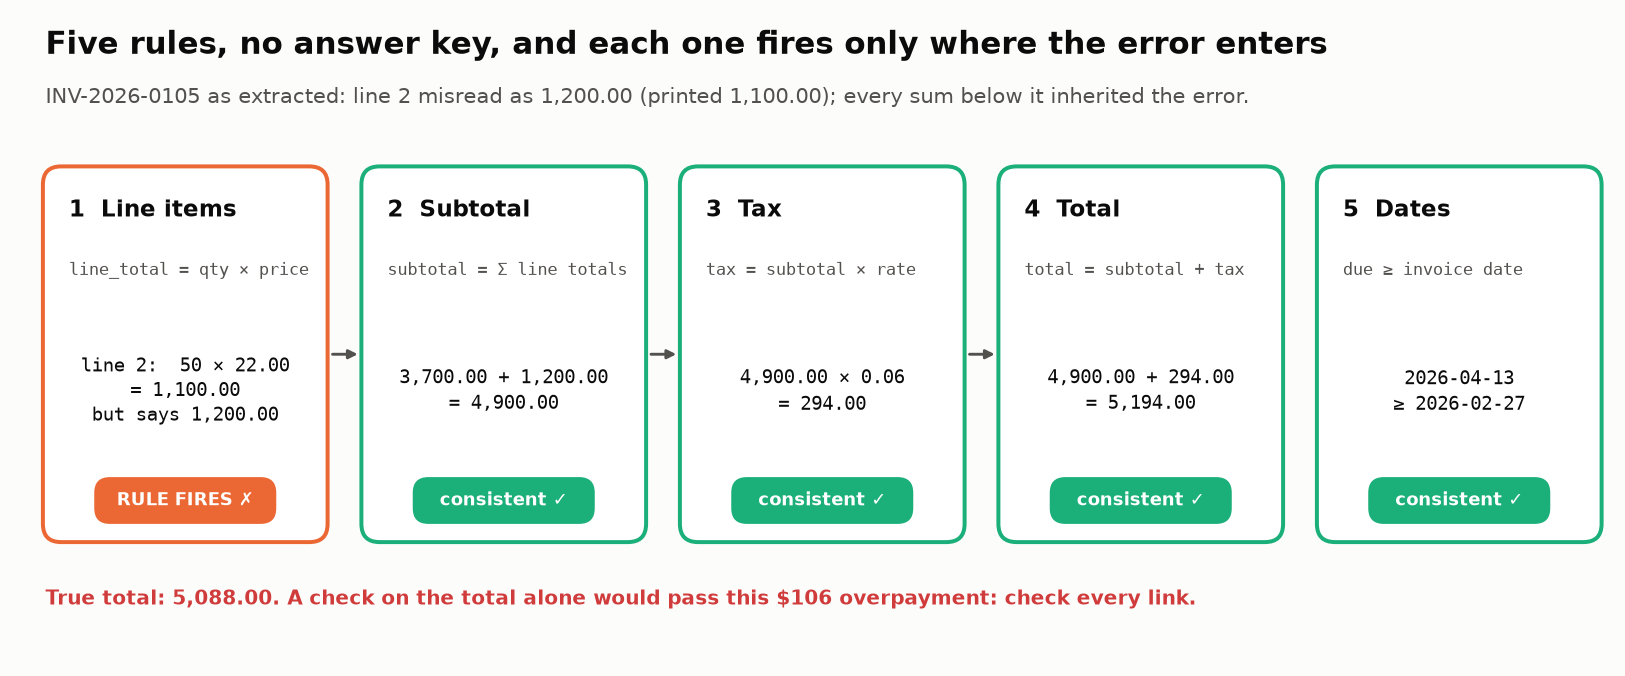

<sub>🖼️ *The five rules you'll encode, run on INV-2026-0105: each fires only where the error enters.*</sub>

#### Why Pydantic?
The grammar enforces **types**, not `total = subtotal + tax`. A validator on a subclass of `Invoice` keeps the provider schema unchanged and adds the semantics on top (`@model_validator(mode="after")` runs once every field has parsed, so the rule sees the whole typed record); in production it validates every response before the ledger.

Expect two kinds of wrong value: **arithmetic** errors (a number disagrees with the others) and **identity** errors (wrong vendor, currency or PO, while every number still agrees).

#### Steps
1. Implement `business_rule_issues(inv)`: return a list of readable issues (empty list = consistent). `inv` is a validated `Invoice`, so use attributes: `inv.subtotal`, `inv.line_items[0].quantity`.
2. Use `TOL` for money math.
3. Set `EXERCISE_8_COMPLETE = True` and re-run. Until then the reference implementation runs, so the rest of the notebook works.

> **🔮 Predict:** of the 10 invoices with real errors (after the gold fix), how many can rules catch with no labels (`rules_catch`)? Which are hopeless for rules?

> 📘 **Concept · Business rule (cross-field consistency)**
>
> **What it is:** a relationship that holds on every valid invoice (line totals sum to the subtotal; subtotal + tax = total; due date ≥ issue date), checked on the output alone.
>
> **What it can't tell you:** anything self-consistent: a wrong payee, a wrong currency or a copied PO number breaks no arithmetic.
>
> **Anchor:** rules catch the wrong tax on 0102 and the bad line total on 0105, and miss the CAD invoice booked as USD.

In [ ]:
TOL = 0.01                    # one cent of rounding slack for money math
EXERCISE_8_COMPLETE = False   # 🧠 set True after you implement the TODOs below


def business_rule_issues(inv: Invoice) -> list[str]:
    """Rules every valid invoice obeys. Return a list of issue strings (empty = consistent)."""
    if not EXERCISE_8_COMPLETE:
        return _reference_business_rule_issues(inv)
    issues = []
    # TODO 1: each line item: |quantity × unit_price − line_total| ≤ TOL
    # TODO 2: |sum of line totals − subtotal| ≤ TOL
    # TODO 3: |subtotal × tax_rate − tax_amount| ≤ TOL
    # TODO 4: |subtotal + tax_amount − total_amount| ≤ TOL
    # TODO 5: if due_date is not None, due_date ≥ invoice_date   (hint: date.fromisoformat)
    raise NotImplementedError("Implement the TODOs, then delete this line.")
    return issues


class CheckedInvoice(Invoice):
    """Same schema as Invoice, plus the business rules the grammar cannot enforce."""

    @model_validator(mode="after")
    def _business_rules(self):
        issues = business_rule_issues(self)
        if issues:
            raise ValueError(" | ".join(issues))
        return self


def rule_check(record) -> list[str]:
    """Validate one raw record; return its rule violations (empty list = passes)."""
    try:
        CheckedInvoice.model_validate(record)
        return []
    except PydanticValidationError as e:
        return [part for err in e.errors() for part in err["msg"].removeprefix("Value error, ").split(" | ")]


rule_results = {iid: rule_check(rec) for iid, rec in outputs.items()}
for iid, issues in rule_results.items():
    if issues:
        print(f"⚠️ {iid}: " + "; ".join(issues))
if not EXERCISE_8_COMPLETE:
    print("\n📝 Exercise 8 reference fallback is active. Implement the TODOs and set EXERCISE_8_COMPLETE = True.")

In [ ]:
# @title 📊 Coverage grid: which layer catches which broken invoice (hidden · 30 lines · expand if curious)
# --- Coverage: which layer catches which broken invoice? (vs the corrected gold) --------------
wrong = scored_fixed[~scored_fixed["correct"]].groupby("invoice")["field"].apply(list)
broken = list(wrong.index)
layers = {"Schema (Task 3)": lambda i: bool(schema_results[i]),
          "Business rules (Task 8)": lambda i: bool(rule_results[i]),
          "Gold comparison (Task 5)": lambda i: True}
grid = [[layers[name](i) for i in broken] for name in layers]
caught_by_rules = [i for i in broken if rule_results[i]]
missed = [i for i in broken if not rule_results[i]]
ARITH = MONEY | {"line_items", "tax_rate"}
missed_fields = sorted({f for i in missed for f in wrong[i]})
flagged_clean = [i for i, iss in rule_results.items() if iss and i not in broken]

fig, ax = plt.subplots(figsize=(11, 2.9))
for r, row in enumerate(grid):
    for c, hit in enumerate(row):
        ax.add_patch(plt.Rectangle((c, r), 0.94, 0.88, color=STATUS["good"] if hit else "#e9e8e4"))
        ax.text(c + 0.47, r + 0.44, "caught" if hit else "missed", ha="center", va="center", fontsize=9,
                color="white" if hit else "#52514e", weight="bold" if hit else "normal")
ax.set_xlim(0, len(broken)); ax.set_ylim(len(grid), 0)
ax.set_yticks([r + 0.44 for r in range(len(grid))], list(layers))
ax.set_xticks([c + 0.47 for c in range(len(broken))],
              [f"{i[-4:]}\n" + "\n".join(f.replace("_amount", "").replace("_", " ") for f in wrong[i][:2]) for i in broken],
              fontsize=8.5)
ax.tick_params(length=0); ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
only_identity = all(f not in ARITH for f in missed_fields)
ax.set_title("Rules catch arithmetic, not identity" if only_identity else
             f"Business rules caught {len(caught_by_rules)} of {len(broken)} broken invoices")
plt.tight_layout()
plt.show()

In [ ]:
tiles([
    ("Broken invoices (corrected gold)", len(broken), f"of {len(outputs)}", None),
    ("Caught by schema", sum(grid[0]), "constrained decoding", "critical" if not any(grid[0]) else "warning"),
    ("Caught by rules, no labels", f"{len(caught_by_rules)}/{len(broken)}", "runs on 100% of traffic", "warning"),
    ("False alarms on clean invoices", len(flagged_clean), "rule fired, record correct", "good" if not flagged_clean else "warning"),
])
insight(
    f"Rules caught {len(caught_by_rules)} of {len(broken)} broken invoices with zero labels"
    + ("; every miss was an identity error" if only_identity else ""),
    f"Caught ({', '.join(i[-4:] for i in caught_by_rules)}): wrong tax, a bad line total, a misread quantity, a "
    f"transposed total, impossible dates. Missed ({', '.join(i[-4:] for i in missed)}): "
    f"{', '.join(f'`{f}`' for f in missed_fields)}. A wrong payee, a wrong currency or an invented PO number is "
    "*self-consistent*, so no arithmetic rule can see it.\n"
    "**In production (accounts payable / tax):** route every rule violation to a human queue *before* posting, and "
    "close the identity gap with **reference data**: `vendor_name` against the vendor master, the PO number against "
    "purchasing, currency from the printed symbol plus the vendor's country. Deterministic, cheap, and they catch "
    "exactly what rules can't.",
    kind="production",
)

#### Checkpoint ✅
Five ⚠️ lines (one per flagged invoice), a caught/missed grid titled **"Rules catch arithmetic, not identity"**, four tiles and a 🏭 card. If you implemented the exercise, your wording can differ, but the same five invoices must be flagged.

#### Expected Output
```
⚠️ INV-2026-0102: tax 200.00 ≠ 2,090.00 × 0.0825 = 172.43
⚠️ INV-2026-0105: line 2: 50 × 22.00 = 1,100.00, not 1,200.00
⚠️ INV-2026-0106: due 2026-03-04 is before issue 2026-04-03
⚠️ INV-2026-0112: total 3,370.43 ≠ subtotal + tax = 3,307.43
⚠️ INV-2026-0117: line 1: 2 × 45.00 = 90.00, not 540.00

📝 Exercise 8 reference fallback is active. ...
```
Tiles: **10** broken · **0** caught by schema · **5/10** caught by rules · **0** false alarms.

INV-2026-0105: its wrong subtotal, tax and total are consistent *with each other*. Only the line-item rule fires, because the error entered at line 2 and every downstream number inherited it. Check every relationship, not just the last one.

INV-2026-0117 was caught only because the model **copied** the printed line total (540.00) next to its misread quantity. Had it "helpfully" recomputed 2 × 45 = 90 and every sum below it, the record would be wrong *and* self-consistent, and no rule would fire. That is why the prompt says *never compute*; Challenge 🌶️ has you build that invoice.

### 🔍 What Just Happened?

You built the check that runs on **every** invoice in production and measured its blind spot: rules catch arithmetic, never identity.

**Bridge:** a business rule checks one output against itself. What if a vendor sends the *same* invoice in a different format, with day-first dates or no currency line?

🗣️ **Say it to a colleague:** "Rules catch arithmetic for free; identity needs reference data. Route both to a human before posting."

⏱️ **60-second experiment:** set `TOL = 1.00` (a dollar of slack) in the rules cell and re-run it. Which flagged invoice disappears, and would an auditor accept that slack on a tax amount?

### Task 9: 🧠 Your Turn: invariance tests (same invoice, new format, same JSON?) 🛡️

**Stakes:** A vendor changes a date format and your extractor changes a payment date, silently.

#### Goal
One invoice re-rendered in harmless formatting variants, each extracted, and a check that the extraction **doesn't change**. An **invariance test** compares two outputs of the same invoice with each other, so, like a business rule, it needs no label; the only rule is "a formatting change must not change the meaning" (a *metamorphic* test).

#### Setup
- Base document: INV-2026-0107 (Maple Leaf Print Co., CAD), rendered cleanly with ISO dates and a `Currency: CAD` line.
- Extractor: with `PROVIDER = "mock"` a **deterministic stand-in** parses the text, with weaknesses that mimic a model reading the page. With a live provider the cell calls `extract_invoice()`.
- Each **perturbation** (a re-rendering that changes format, not meaning) ends in one of three outcomes:
  - ✅ **invariant**: nothing changed;
  - 🔊 **loud break**: values changed, and the schema or a business rule flagged it;
  - 🔇 **silent break**: values changed, and **every** check still passed. The dangerous one.

#### Steps
1. Run the cell with the 7 provided perturbations.
2. **Your turn:** add at least two of your own to `MY_PERTURBATIONS` (ideas: `"TOTAL:"` → `"TOTAL DUE:"`, a `"Page 1 of 1"` header, OCR noise (scanner misreads) like `O` for `0` in the invoice number, an extra blank line between items) and re-run.

> **🔮 Predict** (`silent_breaks`): which of these break silently? (a) US dates, (b) day-first dates, (c) no thousands separators, (d) decimal comma, (e) currency only as `C$`, (f) items reversed, (g) vendor in capitals.

> 📘 **Concept · Invariance test**
>
> **What it is:** render the same invoice in a harmless new format (day-first dates, no thousands separators, upper-case vendor) and assert the extraction does not change.
>
> **What it can't tell you:** whether the baseline is right; it compares two outputs with each other, so it needs no label and catches format sensitivity only.
>
> **Anchor:** day-first dates change `invoice_date` with no alarm: a silent break; a decimal comma trips a rule: a loud one.

In [ ]:
ROBUST_ID = "INV-2026-0107"
base = GOLD_FIXED[ROBUST_ID]
extract = standin_extract if PROVIDER == "mock" else extract_invoice

PERTURBATIONS = {
    "US dates (MM/DD/YYYY)": lambda inv: render_source(inv, date_style="us"),
    "Day-first dates (DD/MM/YYYY)": lambda inv: render_source(inv, date_style="dayfirst"),
    "No thousands separators": lambda inv: render_source(inv, thousands=False),
    "Decimal comma (1.276,90)": lambda inv: render_source(inv, decimal_comma=True),
    "Currency only as symbol (C$)": lambda inv: render_source(inv, currency_line=False),
    "Line items reversed": lambda inv: render_source(inv, reverse_items=True),
    "Vendor name in capitals": lambda inv: render_source(inv, vendor_upper=True),
}

# 🧠 YOUR TURN: add at least two perturbations of your own (each maps an invoice dict to document text).
MY_PERTURBATIONS = {
    # "TOTAL DUE label": lambda inv: render_source(inv).replace("TOTAL:", "TOTAL DUE:"),
}

canonical = extract(render_source(base))
baseline_ok = all(field_correct(f, canonical[f], base[f]) for f in FIELDS)
print(f"Baseline (clean document) matches gold: {baseline_ok}\n")

rows = []
for name, perturb in {**PERTURBATIONS, **MY_PERTURBATIONS}.items():
    out = extract(perturb(base))
    changed = [f for f in FIELDS if not field_correct(f, out.get(f), canonical.get(f))]
    alarms = schema_errors(out) + (rule_check(out) if not schema_errors(out) else [])
    status = "✅ invariant" if not changed else ("🔊 loud break" if alarms else "🔇 silent break")
    rows.append({"perturbation": name, "outcome": status,
                 "changed fields": ", ".join(f"{f}: {canonical.get(f)!r}→{out.get(f)!r}" for f in changed
                                             if f != "line_items") + (" + line_items" if "line_items" in changed else ""),
                 "first alarm": alarms[0][:60] if alarms else ""})
robust = pd.DataFrame(rows)
display(robust)

In [ ]:
n_breaks = int((robust["outcome"] != "✅ invariant").sum())
n_silent = int((robust["outcome"] == "🔇 silent break").sum())
silent_names = list(robust.loc[robust["outcome"] == "🔇 silent break", "perturbation"])
tiles([
    ("Perturbations", len(robust), "meaning-preserving", None),
    ("Invariant", int((robust["outcome"] == "✅ invariant").sum()), "same JSON", "good"),
    ("Loud breaks", n_breaks - n_silent, "a check fired", "warning" if n_breaks - n_silent else "good"),
    ("Silent breaks", n_silent, "every check passed", "critical" if n_silent else "good"),
])
batch_echo = sorted(set(audit.loc[audit["field"].isin(["invoice_date", "currency"]), "invoice"]))
silent_changes = "; ".join(robust.loc[robust["outcome"] == "🔇 silent break", "changed fields"])
insight(
    f"{n_silent} of {n_breaks} breaking format changes were silent: schema-valid, rule-consistent and wrong",
    f"Silent: {'; '.join(silent_names)}. What changed: {silent_changes}. Nothing complained, because each wrong "
    f"value is well-typed and self-consistent. The real batch already contains both failure modes "
    f"({', '.join(batch_echo)}); with one example of each, no average could have "
    "warned you.\n"
    "**Rule of thumb:** keep an invariance test in your CI suite (continuous integration: the tests run on every code change) for every format your vendors use (locales, date orders, "
    "separators, symbols). Assert *same JSON*, not *valid JSON*.",
    kind="warning",
)

#### 🔬 Why the day-first swap survives testing

INV-2026-0106 and the day-first perturbation both failed the same way: `DD/MM` read as `MM/DD`. Check the whole calendar, not one invoice.

> **🔮 Predict:** write every 2026 date day-first and read it month-first. On what share of days do you get a *real but wrong* date? And of those swaps on Net 30 invoices, what share does Task 8's `due ≥ issue` rule catch?

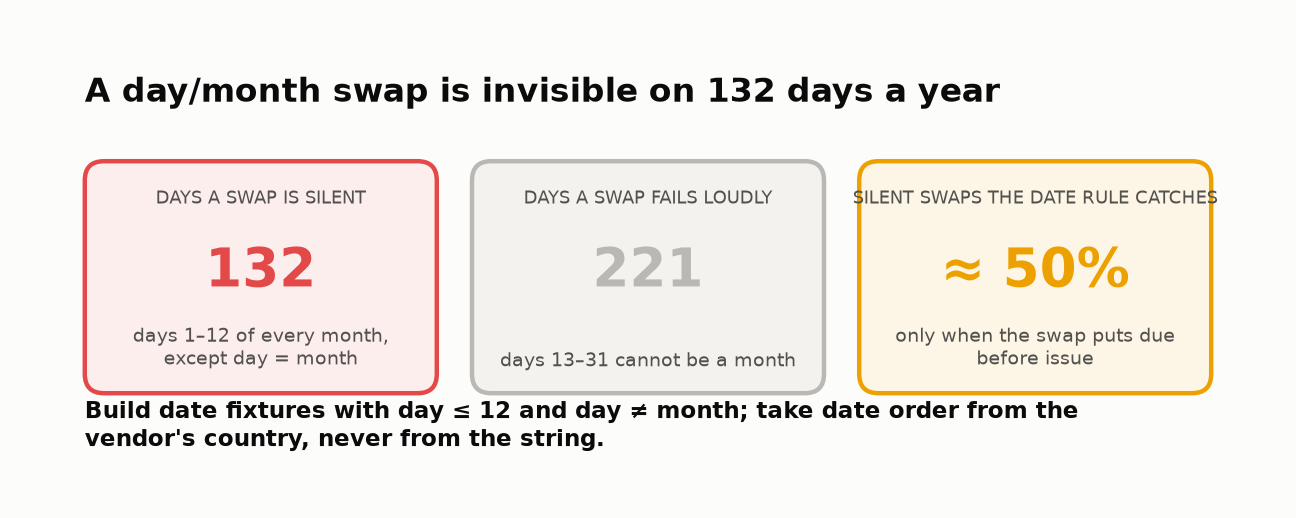
<sub>🖼️ *Run the next cell to compute these from the 2026 calendar.*</sub>

In [ ]:
# 🔬 Every 2026 date written day-first (DD/MM/YYYY), then read month-first, as the stand-in (and many parsers) do
year = [date(2026, 1, 1) + timedelta(days=k) for k in range(365)]


def misread(d):
    try:
        return datetime.strptime(d.strftime("%d/%m/%Y"), "%m/%d/%Y").date()
    except ValueError:        # day 13-31 can't be a month: the parse fails loudly
        return None


swap = {d: "same" if misread(d) == d else "loud" if misread(d) is None else "silent" for d in year}
n_same, n_loud, n_silent_days = (sum(v == k for v in swap.values()) for k in ("same", "loud", "silent"))

# Net 30 invoices where both dates parse but at least one changed: does Task 8's date rule notice?
net30 = [(d, d + timedelta(days=30)) for d in year]
silent_pairs = [(d, due) for d, due in net30 if misread(d) and misread(due) and (misread(d), misread(due)) != (d, due)]
rule_hits = [(d, due) for d, due in silent_pairs if misread(due) < misread(d)]

In [ ]:
# @title 📊 The 2026 calendar grid (hidden · 16 lines · expand if curious)
fig, ax = plt.subplots(figsize=(11, 3.4))
colors = {"same": PALETTE[2], "silent": PALETTE[1], "loud": "#d9d8d4"}
for d, kind in swap.items():
    ax.add_patch(plt.Rectangle((d.day - 1, d.month - 1), 0.9, 0.85, color=colors[kind]))
ax.set_xlim(0, 31); ax.set_ylim(12, 0)
ax.set_xticks([i + 0.45 for i in range(31)], [str(i + 1) for i in range(31)], fontsize=8)
ax.set_yticks([i + 0.42 for i in range(12)], [date(2026, m, 1).strftime("%b") for m in range(1, 13)], fontsize=8.5)
ax.tick_params(length=0); ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_xlabel(f"day of month · orange = silently wrong ({n_silent_days}) · gray = parse fails loudly ({n_loud}) · "
              f"green = unchanged, day = month ({n_same})")
ax.set_title(f"A day/month swap is silent on {n_silent_days} of 365 days: exactly the days 1–12")
plt.tight_layout()
plt.show()

In [ ]:
print(f"Day-first dates in 2026: {n_same} unchanged · {n_silent_days} silently wrong · {n_loud} fail loudly")
print(f"Net 30 invoices whose dates swap silently: {len(silent_pairs)}; caught by due ≥ issue: "
      f"{len(rule_hits)} ({len(rule_hits) / len(silent_pairs):.0%})")
insight(
    f"The swap hides on the {n_silent_days} ambiguous days ({n_silent_days / 365:.0%} of the year), and the date "
    f"rule catches only {len(rule_hits) / len(silent_pairs):.0%} of those",
    f"On days 13–31 a month-first parser crashes ({n_loud} days), so a test set built from dates like 25/03 only "
    "ever sees the loud failure. On days 1–12 the result is a real date, just the wrong one. INV-2026-0106 was "
    "caught only because its swap put the due date before the issue date; across every Net 30 invoice of 2026, "
    f"`due ≥ issue` fires on {len(rule_hits)} of {len(silent_pairs)} silent swaps: a coin flip.\n"
    "**Rule of thumb:** build date fixtures with day ≤ 12 and day ≠ month, and take date order from the vendor's "
    "country, never from the string.",
    kind="surprise",
)


#### Checkpoint ✅
`Baseline (clean document) matches gold: True`, a 7-row table (plus your own rows), four tiles and a ⚠️ card. Then the 🔬 calendar grid and a 🤯 card.

#### Expected Output (provided perturbations only)
| perturbation | outcome | changed fields |
|---|---|---|
| US dates (MM/DD/YYYY) | ✅ invariant | |
| Day-first dates (DD/MM/YYYY) | 🔇 silent break | invoice_date: '2026-02-05'→'2026-05-02', due_date: '2026-03-07'→'2026-07-03' |
| No thousands separators | ✅ invariant | |
| Decimal comma (1.276,90) | 🔊 loud break | subtotal: 1130.0→1.13, tax_amount: 146.9→14690.0, total_amount: 1276.9→1.2769 + line_items (first alarm: `subtotal 1.13 ≠ sum of lines 113,000.00`) |
| Currency only as symbol (C$) | 🔇 silent break | currency: 'CAD'→'USD' |
| Line items reversed | ✅ invariant | |
| Vendor name in capitals | ✅ invariant | |

Tiles: **7** perturbations · **4** invariant · **1** loud · **2** silent. Card: **2 of 3 breaking format changes were silent**.

🔬 Calendar, titled **"A day/month swap is silent on 132 of 365 days: exactly the days 1–12"**:
```
Day-first dates in 2026: 12 unchanged · 132 silently wrong · 221 fail loudly
Net 30 invoices whose dates swap silently: 135; caught by due ≥ issue: 66 (49%)
```
Card: **The swap hides on the 132 ambiguous days (36% of the year), and the date rule catches only 49% of those**.

### ✍️ Robustness Analysis

1. **Which of your own perturbations broke the extractor, and was the break loud or silent?** *Your answer...*
2. **Why did "items reversed" and "vendor in capitals" stay invariant?** (Hint: the comparators from Task 5. Would a naive `==` have called them breaks?) *Your answer...*
3. **Which two invariance tests would you add to CI first for your own product?** *Your answer...*

**Bridge:** six checks, six kinds of evidence. Now turn them into a decision your manager can act on.

🗣️ **Say it to a colleague:** "Assert *same JSON*, not *valid JSON*. And build date fixtures with day ≤ 12, or you'll only ever see the loud failure."

🧭 **Where you are:** Act 3 of 3 (Task 10): turn six checks into one decision, priced.

### Task 10: Go / no-go, with the uncertainty attached 🚦

**Stakes:** BLOCK costs money and so does SHIP; the gates say which, with the uncertainty attached.

#### Goal
A SHIP / SHIP WITH CAUTION / BLOCK decision from explicit **release gates**: one pass/fail threshold per metric, where the release passes only if every gate passes.

#### The 2026 gates

| Gate | Threshold | Why this gate |
|---|---|---|
| Schema validity | = 100% | Free with strict mode; anything less is a pipeline bug, not a model trait |
| Critical-record accuracy (corrected gold) | ≥ 95%, and the 95% CI lower bound ≥ 90% | What customers experience; n = 20 is small, so the interval decides |
| Hallucination rate on empty fields | ≤ 2% | Invented values pass every other check |
| Silent invariance breaks | 0 | Silent failures reach the ledger unseen |

**The weakest gate decides.** Averaging gates would let a perfect schema score hide a 35% critical-error rate.

#### Steps
1. Run the cell.
2. Write your recommendation in the ✍️ cell. If you'd overrule the gates, say why.

> **🔮 Predict:** ship, ship with caution, or block? Which gate fails by the widest margin?

In [ ]:
crit_k, n = S2["crit_records"], S2["n"]
crit_lo, crit_hi = wilson(crit_k, n)
gates = [  # (gate, measured value, detail, target, passed?)
    ("Schema validity", f"{schema_rate:.0%}", f"{n_valid}/{len(outputs)}", "= 100%", schema_rate == 1.0),
    ("Critical-record accuracy", f"{crit_k / n:.0%}", f"95% CI {crit_lo:.0%}–{crit_hi:.0%}", "≥ 95%, CI low ≥ 90%",
     crit_k / n >= 0.95 and crit_lo >= 0.90),
    ("Hallucination rate", f"{hall_rate2:.0%}", f"{n_hall2}/{gold_empty2} empty fields", "≤ 2%", hall_rate2 <= 0.02),
    ("Silent invariance breaks", str(n_silent), f"of {len(robust)} perturbations", "0", n_silent == 0),
]
tiles([(name, value, f"{detail} · gate {target}", "good" if ok else "critical") for name, value, detail, target, ok in gates])

failed = [g for g in gates if not g[4]]
only_ci_short = len(failed) == 1 and failed[0][0] == "Critical-record accuracy" and crit_k / n >= 0.95
decision = "SHIP" if not failed else ("SHIP WITH CAUTION" if only_ci_short else "BLOCK")
reasons = [f"**{name}: {value}** ({detail}; gate {target})" for name, value, detail, target, ok in failed]
reasons += [
    f"Schema validity was {schema_rate:.0%} throughout and predicted none of this.",
    "**Fix first:** locale-aware dates (vendor country decides DD/MM vs MM/DD) · currency from symbol + vendor country · "
    "vendor-master and PO lookups · prompt rule against computing due dates · route every business-rule violation to "
    "human review before posting.",
    f"**Then re-measure** on a larger, audited sample: with n = {n}, even a perfect run's 95% CI lower bound is only "
    f"{wilson(n, n)[0]:.0%}, so this gate cannot pass until you label at least {next(k for k in range(n, 500) if wilson(k, k)[0] >= 0.90)} invoices.",
]
verdict(decision, reasons)

#### Checkpoint ✅
Four gate tiles (three red, one green) and a decision banner.

#### Expected Output
Tiles: Schema validity **100%** ✅ · Critical-record accuracy **65%** ⛔ (95% CI 43%–82%) · Hallucination rate **8%** ⛔ (2/24) · Silent invariance breaks **2** ⛔.
```
🛑 BLOCK
 • Critical-record accuracy: 65% (95% CI 43%–82%; gate ≥ 95%, CI low ≥ 90%)
 • Hallucination rate: 8% (2/24 empty fields; gate ≤ 2%)
 • Silent invariance breaks: 2 (of 7 perturbations; gate 0)
 • Schema validity was 100% throughout and predicted none of this.
 • Fix first: ...
 • Then re-measure on a larger, audited sample: with n = 20, even a perfect run's 95% CI lower bound is only 84%,
   so this gate cannot pass until you label at least 35 invoices.
```

#### 💸 What does each policy cost? (the simulator)

BLOCK is a decision about money. Three ways to run this extractor tomorrow: auto-post everything, send only rule-flagged invoices (Task 8) to a human, or review every invoice. Each escaped critical error and each human review has a cost; the defaults are **illustrative**, so set your own. Error bars are the Wilson range of the escape rate at n = 20.

> 🎛️ **Try it:** drag *cost per escaped error* down until "review rule-flagged" becomes the cheapest. Note where it flips, then watch how wide the error bars are.

In [ ]:
# @title 🧰 Cost-of-errors simulator: the three policies and the chart function (hidden · 36 lines · expand if curious)
# 💸 Cost-of-errors simulator: what each operating policy costs per month (illustrative costs; set your own)
crit_wrong = set(scored_fixed.loc[scored_fixed["field"].isin(CRITICAL) & ~scored_fixed["correct"], "invoice"])
flagged = {i for i, issues in rule_results.items() if issues}
N_INV = len(outputs)
POLICIES = {  # policy -> (invoices a human reviews, invoices that escape with a wrong critical field)
    "Auto-post everything": (set(), crit_wrong),
    "Review rule-flagged invoices": (flagged, crit_wrong - flagged),
    "Review every invoice": (set(outputs), set()),
}


def show_policy_costs(volume=10_000, cost_error=150, cost_review=4.0):
    rows = []
    for name, (reviewed, escaped) in POLICIES.items():
        lo, hi = (0.0, 0.0) if len(reviewed) == N_INV else wilson(len(escaped), N_INV)  # full review: no escapes
        cost = lambda esc: volume * (len(reviewed) / N_INV * cost_review + esc * cost_error)
        rows.append((name, len(reviewed), len(escaped), cost(len(escaped) / N_INV), cost(lo), cost(hi)))
    best = min(rows, key=lambda r: r[3])[0]
    fig, ax = plt.subplots(figsize=(9, 2.6))
    for y, (name, n_rev, n_esc, c, c_lo, c_hi) in enumerate(rows[::-1]):
        ax.barh(y, c, color=PALETTE[2] if name == best else "#b9b8b3", height=0.55)
        ax.errorbar(c, y, xerr=[[c - c_lo], [c_hi - c]], fmt="none", ecolor="#52514e", capsize=4, lw=1.2)
        ax.text(c_hi + max(r[5] for r in rows) * 0.02, y, f"${c:,.0f}", va="center", fontsize=10,
                weight="bold", parse_math=False)
    ax.set_yticks(range(len(rows)), [r[0] for r in rows[::-1]])
    ax.set_xlim(0, max(r[5] for r in rows) * 1.25)
    ax.xaxis.set_major_formatter(lambda x, _: f"${x / 1000:,.0f}k")
    ax.set_xlabel(f"cost per month at {volume:,} invoices · bars = 95% Wilson range of the escape rate (n = {N_INV})")
    ax.set_title(f"At ${cost_error:,g} per escaped error and ${cost_review:,g} per review, {best} is cheapest",
                 parse_math=False)
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.show()
    for name, n_rev, n_esc, c, _, _ in rows:
        print(f"{name}: {n_rev}/{N_INV} reviewed, {n_esc}/{N_INV} escape → ${c:,.0f} / month")

In [ ]:
# 👀 Look at: the whiskers are the Wilson range of the escape rate at n = 20; the cheapest policy can change inside them.
show_policy_costs()   # the default view (this is what Run All shows)

e_k, r_flag = len(crit_wrong - flagged), len(flagged) / N_INV
if e_k:
    e_lo, e_hi = wilson(e_k, N_INV)
    be, be_lo, be_hi = (1 - r_flag) / (e_k / N_INV), (1 - r_flag) / e_hi, (1 - r_flag) / e_lo
    insight(
        f"Reviewing everything beats reviewing only rule-flagged invoices once an escaped error costs more than "
        f"{be:.1f} reviews",
        f"Rule-flagged review sends {len(flagged)} of {N_INV} invoices to a human and still lets {e_k} through with a "
        f"wrong critical field ({', '.join(sorted(i[-4:] for i in crit_wrong - flagged))}): the identity errors no rule "
        f"sees. And {e_k}/{N_INV} is a 20-invoice rate: its 95% range is {e_lo:.0%}–{e_hi:.0%}, so the break-even is "
        f"anywhere from {be_lo:.1f}× to {be_hi:.0f}× the cost of a review.\n"
        "**Rule of thumb:** price the escapes, not the accuracy, and check that your policy choice survives the whole "
        "error bar before you commit to it.",
    )

In [ ]:
# @title 🎛️ Sliders for your own volume, error and review costs (hidden · 20 lines · move them after Run All)
try:
    import ipywidgets as W
    _sl = {"volume": W.IntSlider(value=10_000, min=1_000, max=100_000, step=1_000, description="invoices / month",
                                 continuous_update=False, style={"description_width": "150px"}),
           "cost_error": W.IntSlider(value=150, min=0, max=500, step=5, description="$ per escaped error",
                                     continuous_update=False, style={"description_width": "150px"}),
           "cost_review": W.FloatSlider(value=4.0, min=0.5, max=20.0, step=0.5, description="$ per review",
                                        continuous_update=False, style={"description_width": "150px"})}
    _out = W.Output()

    def _redraw(_=None):
        with _out:
            _out.clear_output(wait=True)
            show_policy_costs(**{k: s.value for k, s in _sl.items()})

    for _s in _sl.values():
        _s.observe(_redraw, names="value")
    display(W.HTML("<b>🎛️ Your assumptions</b> (move a slider; your view appears below)"),
            W.VBox(list(_sl.values())), _out)
except ImportError:
    print("ipywidgets not available: call show_policy_costs(volume=..., cost_error=..., cost_review=...) instead.")


#### Checkpoint ✅ (simulator, at the default assumptions)
A chart titled **"At \$150 per escaped error and \$4 per review, Review every invoice is cheapest"** and a 💡 card.
```
Auto-post everything: 0/20 reviewed, 7/20 escape → $525,000 / month
Review rule-flagged invoices: 5/20 reviewed, 2/20 escape → $160,000 / month
Review every invoice: 20/20 reviewed, 0/20 escape → $40,000 / month
```
Card: **Reviewing everything beats reviewing only rule-flagged invoices once an escaped error costs more than 7.5 reviews** (n = 20 range: 2.5×–27×).

### ✍️ Your Go / No-Go Recommendation

1. **Decision** (SHIP / SHIP WITH CAUTION / BLOCK): *Your answer...*
2. **The three numbers that drove it:** *Your answer...*
3. **What would change your mind?** (Which fixes, re-measured on how many invoices?) *Your answer...*
4. **What would you monitor on 100% of production traffic** (no labels), and what would you sample for labelling each week? *Your answer...*

### 🔍 What Just Happened?

Six checks became one decision with its uncertainty attached. The opening dashboard said "100% valid"; the gates say **BLOCK**, name the fixes to make first, and the simulator prices what to run in the meantime.

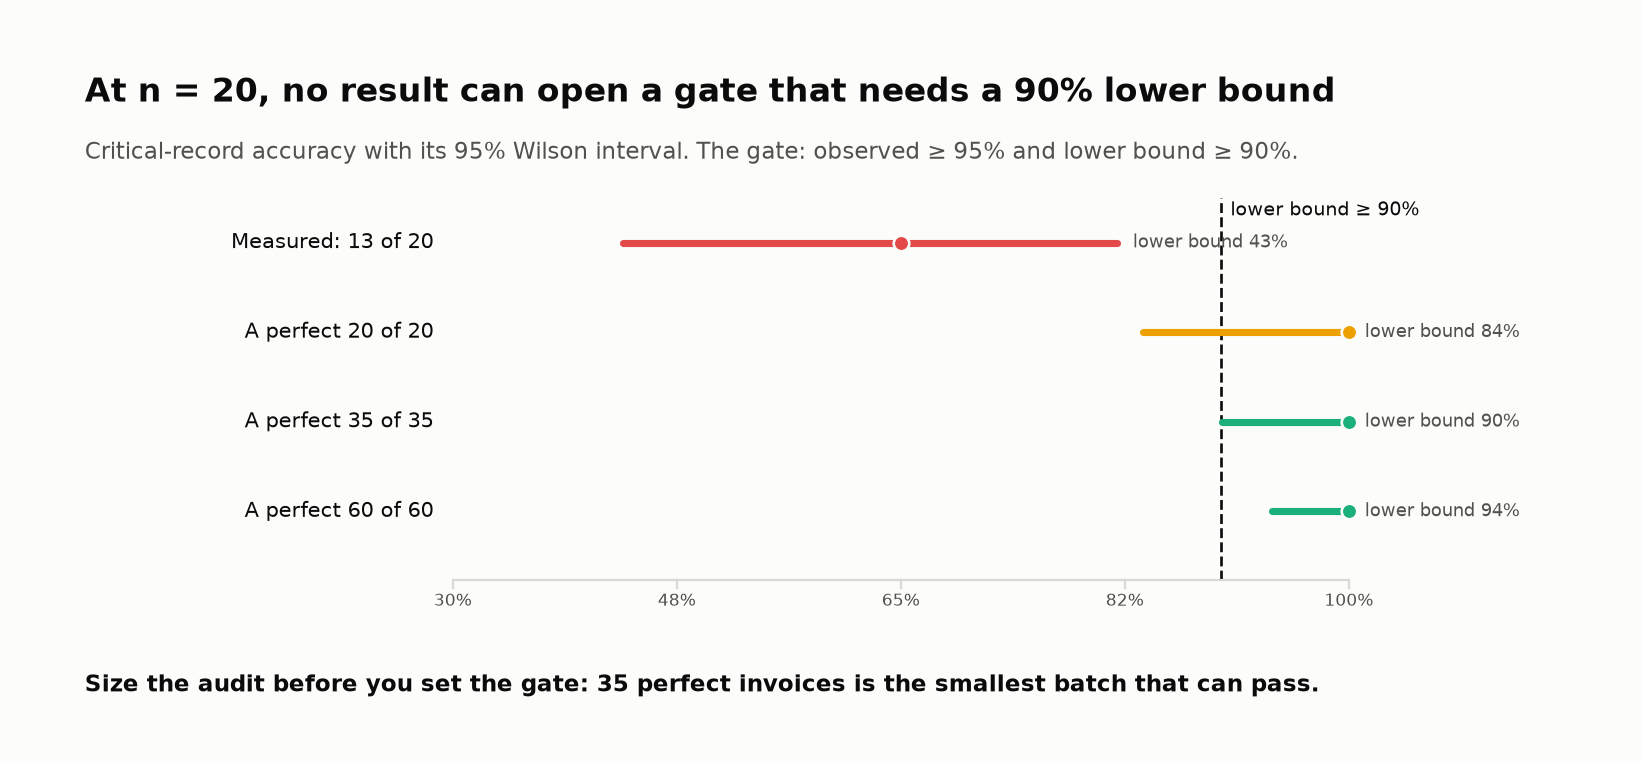
<sub>🖼️ *Challenge 3 asks how many invoices you must audit; this is why the answer is not 20.*</sub>

🗣️ **Say it to a colleague:** "Price the escapes, not the accuracy. And at n = 20, no result can open a gate that needs a 90% lower bound."

---

## ✅ Validation / Success Criteria

You have completed this lab if you can point to:

- ✅ Schema validation results for the strict batch (100%) and the legacy outputs (0/2), and one sentence on why the 100% is uninformative
- ✅ Your impact weights and critical-field list, with a written justification
- ✅ Field accuracy, weighted field accuracy, record accuracy and critical-record accuracy for the batch
- ✅ Hallucination and omission rates on nullable fields, plus the provenance of each invented value
- ✅ Your 🕵️ auditor score, and an audit table that separates model errors, label errors and ambiguous cases, with the corrected metrics
- ✅ A working `business_rule_issues()` (with `EXERCISE_8_COMPLETE = True`) that flags the same 5 invoices as the reference
- ✅ An invariance table including at least two perturbations of your own
- ✅ A SHIP / BLOCK recommendation that cites specific gates, numbers and the cost of the policy you'd run instead

---

## 🛠️ Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| `ModuleNotFoundError: jsonschema` | Install cell skipped | Run the install cell, then restart the runtime |
| `NameError: outputs` / `GOLD_FIXED` / `scored_fixed` | A cell above was skipped | *Runtime → Run before* (Colab) or run all cells above in order |
| `NotImplementedError: Implement the TODOs` | `EXERCISE_8_COMPLETE = True` but TODOs not written | Finish the TODOs or set the flag back to `False` |
| Task 8 flags clean invoices (false alarms > 0) | Tolerance too tight, or comparing floats with `==` | Use `abs(a - b) > TOL`; `TOL = 0.01` |
| Task 8 flags fewer than 5 invoices | A rule is missing or compares the wrong fields | Compare your flagged list with the Expected Output; the line-item rule must check *every* item |
| Your numbers differ slightly from Expected Output | You set your own weights in Task 4 | Expected; record-level metrics depend on which fields you call critical |
| Every number differs | `PROVIDER` is not `"mock"` | Live models produce different errors; compare with the Expected Output only in mock mode |
| `pydantic_core... model_dump` / `parse` errors in live mode | Old SDK versions | `pip install -U openai anthropic`; `responses.parse` and `messages.parse` need current SDKs |
| Anthropic live call raises `stop_reason='refusal'` or `'max_tokens'` | The model declined or ran out of tokens | Inspect the document; raise `max_tokens`; never treat a partial record as valid |

---

## 🚀 Stretch Goal or Extension

1. **Reason free, constrain late, measured.** Add a `reasoning: str` field as the *first* field of a copy of `Invoice` (or run an unconstrained "think" call before the constrained one) and compare record accuracy with the plain schema on a live provider. Report both with Wilson intervals: is the difference bigger than the noise?
2. **Locale rule for ambiguous dates.** Use the vendor address country to decide DD/MM vs MM/DD and re-run the Task 7 audit. Do the two 🧑‍⚖️ rows resolve?
3. **Make it CI** (continuous integration). Wrap Tasks 3, 8 and 9 into `pytest` tests (or a suite in Promptfoo, Inspect AI or DeepEval, three open-source eval frameworks) that fail the build on any schema error, any rule violation in the golden set, or any silent invariance break.

### 🏆 Challenge exercises

Three problems at rising difficulty. Each starter cell runs as shipped and checks your answer with ✅ / ❌. Worked solutions are in the instructor guide.

#### 🌶️ Challenge 1: Forge a perfect-looking wrong invoice

**Stakes:** this is the invoice that gets paid, because every automatic check said yes.

Edit `forged` (a copy of the true INV-2026-0101) so that it is **schema-valid**, passes **all five business rules**, and pays a `total_amount` at least **$100** away from the truth. Then answer: which check from this lab still catches it, without a gold label?

This is the invoice a model produces when it misreads one quantity and then "helpfully" recomputes every sum.

<details><summary>💡 Hint</summary>

Change one line item's `quantity`, then recompute its `line_total`, the `subtotal`, `tax_amount` (round to the cent with `_money`) and `total_amount`, the way `_invoice()` does. For the last question, look at what Task 7's `supported()` needs as input.

</details>

In [ ]:
# 🌶️ CHALLENGE 1: every label-free check in Tasks 3 and 8 accepts it, yet it pays the wrong amount.
truth = GOLD_FIXED["INV-2026-0101"]
forged = deepcopy(truth)
# TODO: edit `forged` here, e.g. forged["line_items"][0]["quantity"] = ..., and keep every rule satisfied.

c1 = {"schema-valid (Task 3)": not schema_errors(forged)}
c1["passes all business rules (Task 8)"] = c1["schema-valid (Task 3)"] and not rule_check(forged)
c1["total off by ≥ $100"] = abs(forged["total_amount"] - truth["total_amount"]) >= 100
for name, ok in c1.items():
    print(f"{'✅' if ok else '❌'} {name}")
if all(c1.values()):
    ungrounded = [f for f in FIELDS if not supported(f, forged[f], SOURCES["INV-2026-0101"])]
    print(f"\n🔎 But supported() finds these values nowhere in the source: {ungrounded}")
    print("   supported() needs the document, not a gold label: it can run on every invoice in production.")
else:
    print("\n📝 Not forged yet: all three checks must show ✅.")


#### 🌶️🌶️ Challenge 2: Close the identity gap

**Stakes:** the five invoices the rules missed are the ones that pay the wrong vendor in the wrong currency.

Task 8's rules missed five broken invoices (`missed`). Write `identity_issues(rec)` using only the extraction and two pieces of **reference data** an accounts-payable system already holds: the vendor master and the PO register. Target: catch **at least 4 of the 5** with **zero false alarms** on the 10 correct invoices.

<details><summary>💡 Hint</summary>

Compare names with `norm_name()` so "LLC" differences don't fire. One of the five misses isn't an identity error at all: it breaks a relationship between `payment_terms` and `due_date` that Task 8 never encoded. The fifth (an omitted PO) is the hard one: what rule would catch it, and which invoice would it wrongly flag?

</details>

In [ ]:
# 🌶️🌶️ CHALLENGE 2: catch Task 8's misses with zero gold labels, using reference data AP already has.
VENDOR_MASTER = {r["vendor_name"]: r["currency"] for r in _TRUTH.values()}   # approved vendor → billing currency
PO_REGISTER = {r["po_number"]: r["vendor_name"] for r in _TRUTH.values() if r["po_number"]}  # PO → vendor


def identity_issues(rec) -> list[str]:
    """Problems visible from the record plus reference data alone (empty list = looks fine)."""
    issues = []
    # TODO 1: vendor_name is not in VENDOR_MASTER (compare with norm_name)
    # TODO 2: currency differs from the vendor's billing currency
    # TODO 3: po_number is set, but PO_REGISTER doesn't have it or issued it to another vendor
    # TODO 4: a payment-terms rule: what must due_date be when terms are "Due on receipt"?
    return issues


c2 = {iid: identity_issues(rec) for iid, rec in outputs.items()}
clean = [i for i in outputs if i not in broken]
caught2, false2 = [i for i in missed if c2[i]], [i for i in clean if c2[i]]
print(f"Task 8 misses caught: {len(caught2)}/{len(missed)} ({', '.join(i[-4:] for i in caught2) or 'none yet'})")
print(f"False alarms on the {len(clean)} correct invoices: {len(false2)} ({', '.join(i[-4:] for i in false2) or 'none'})")
print("✅ Identity gap closed" if len(caught2) >= 4 and not false2 else
      "❌ Target: catch at least 4 of the 5 misses with 0 false alarms")


#### 🌶️🌶️🌶️ Challenge 3: How many invoices must you audit to ship?

**Stakes:** an audit too small to pass its own gate blocks a good model forever; one too large burns the labelling budget.

You fix everything, and v2's **true** critical-record accuracy is **97%**. Task 10's gate needs an observed rate ≥ 95% *and* a Wilson lower bound ≥ 90%.

1. `p_pass(p, n)`: the probability that a model with true rate `p` passes on `n` audited invoices. (Each invoice is right with probability p, so the count k that come out right follows a **binomial distribution**: P(k) = C(n, k)·pᵏ·(1−p)ⁿ⁻ᵏ.)
2. `n_typical`: the smallest n at which a run scoring exactly `round(0.97 * n)` passes.
3. Report `p_pass(0.97, n_typical)`. Is a "typical" run a safe bet?
4. `n_80`: the smallest n with at least an 80% chance to pass. Then read the chart: why is it a sawtooth, and what does that mean when someone says "just add a few more invoices"?

<details><summary>💡 Hint</summary>

`gate_passes(k, n)` is given; `p_pass` sums `comb(n, k) * p**k * (1 - p)**(n - k)` over the k that pass. For the sawtooth, print how many failures the gate allows (n minus the smallest passing k) for each n, and watch where that number changes.

</details>

In [ ]:
# 🌶️🌶️🌶️ CHALLENGE 3: audit size, as a probability rather than a guess.
from math import comb

TRUE_RATE = 0.97


def gate_passes(k, n):
    """Task 10's critical-record gate for k fully-critical-correct invoices out of n."""
    return k / n >= 0.95 and wilson(k, n)[0] >= 0.90


def p_pass(p, n):
    """P(the gate passes) for a model whose true rate is p, audited on n invoices."""
    return None   # TODO: sum the binomial probabilities of every k with gate_passes(k, n)


n_typical = None  # TODO: smallest n where gate_passes(round(TRUE_RATE * n), n)
n_80 = None       # TODO: smallest n where p_pass(TRUE_RATE, n) >= 0.80

ref3 = _reference_challenge3(TRUE_RATE)
if p_pass(TRUE_RATE, 50) is None or n_typical is None or n_80 is None:
    print("📝 TODO: implement p_pass, then set n_typical and n_80.")
else:
    p_typ = p_pass(TRUE_RATE, ref3["n_typical"])
    print(f"{'✅' if n_typical == ref3['n_typical'] else '❌'} n_typical = {n_typical}")
    print(f"{'✅' if abs(p_typ - ref3['p_typical']) < 1e-9 else '❌'} P(pass) at n = {ref3['n_typical']}: {p_typ:.1%}")
    print(f"{'✅' if n_80 == ref3['n_80'] else '❌'} n_80 = {n_80}")
    ns = list(range(20, 201))
    fig, ax = plt.subplots(figsize=(9, 3.2))
    ax.plot(ns, [p_pass(TRUE_RATE, k) for k in ns], color=PALETTE[0])
    ax.axhline(0.8, color="#b9b8b3", lw=1, ls="--")
    ax.yaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
    ax.set_xlabel("invoices audited (n)"); ax.set_ylabel("P(gate passes)")
    ax.set_title("TODO: write the takeaway as the title")
    plt.tight_layout(); plt.show()


#### 🌶️🌶️ Challenge 4: Paid twice (🏦 accounts-payable variant)

**Stakes:** every check in this lab looks at one record at a time. The most expensive extraction error in accounts payable is paying the same invoice twice, and no per-record check can see it.

Two invoices arrive after the batch. **INV-2026-0121** is Summit Office Furniture re-issuing INV-2026-0113 two days later with a new number (their system does that after a correction). **INV-2026-0122** is CloudServ Pro's April subscription: same vendor and amount as March, and perfectly legitimate.

1. Run the cell: both new records pass the schema and every business rule. Then finish `find_duplicates(batch)` so it flags pairs that share a vendor and a total and were issued close together.
2. Set `WINDOW_DAYS`. Too small misses the re-issue; too large flags the subscription. The auto-check wants exactly one pair.
3. One sentence: why is the window a *policy* decision rather than a modelling one, and who in finance should set it?

<details><summary>💡 Hint</summary>

`norm_name` and `same_cents` from Task 5 already handle the upper-case vendor and the cents. `date.fromisoformat` gives you the day gap. Two days apart is a re-issue; thirty-one days apart is a billing cycle; anything between is the policy you must write down.
</details>

In [ ]:
# ============================================================================
# 🌶️🌶️ CHALLENGE 4: paid twice (runs as shipped; finish the TODO and set WINDOW_DAYS)
# ============================================================================
WINDOW_DAYS = None     # 👈 (2) same vendor + same total within this many days = a resubmission, not a recurring charge

resubmitted = deepcopy(outputs["INV-2026-0113"])         # the vendor re-issued the invoice with a new number
resubmitted.update(invoice_number="INV-2026-0121", invoice_date="2026-03-20", due_date="2026-04-19",
                   vendor_name="SUMMIT OFFICE FURNITURE")
recurring = deepcopy(outputs["INV-2026-0111"])           # CloudServ Pro bills the same amount every month
recurring.update(invoice_number="INV-2026-0122", invoice_date="2026-04-01", due_date="2026-05-01")
batch_plus = {**outputs, "INV-2026-0121": resubmitted, "INV-2026-0122": recurring}

for iid in ("INV-2026-0121", "INV-2026-0122"):
    alarms = schema_errors(batch_plus[iid]) or rule_check(batch_plus[iid])
    print(f"{iid}: {'✅ passes the schema and every business rule' if not alarms else alarms}")


def find_duplicates(batch):
    """Pairs of invoice ids that look like one invoice submitted twice."""
    pairs = set()
    if WINDOW_DAYS is None:
        return pairs
    recs = list(batch.items())
    for k, (ia, a) in enumerate(recs):
        for ib, b in recs[k + 1:]:
            looks_duplicate = False   # TODO (1): same vendor (norm_name), same total (same_cents), dates within WINDOW_DAYS
            if looks_duplicate:
                pairs.add(frozenset({ia, ib}))
    return pairs


EXPECTED = {frozenset({"INV-2026-0113", "INV-2026-0121"})}
found = find_duplicates(batch_plus)
hit_recurring = any("INV-2026-0122" in p for p in found)
print("✅" if found == EXPECTED else "❌",
      f"{len(found)} pair(s) flagged · re-issue {'caught' if EXPECTED <= found else 'missed'} · "
      f"recurring CloudServ charge {'wrongly flagged' if hit_recurring else 'left alone'}")

#### 🌶️🌶️🌶️ Challenge 5: Your batch is not your traffic

**Stakes:** next quarter the product launches in Canada. The eval batch is 90% USD invoices; production will be 60%. A number measured on the wrong mix is a number about a different product.

1. Run the cell. It splits critical-record accuracy by currency (with Wilson intervals) and projects it onto `PRODUCTION_MIX`. 🔮 **Predict** before you look: does the projection land **A)** within 5 points of the batch rate, **B)** 5–15 points lower, or **C)** more than 15 points lower?
2. Set `PROJECTED_PCT` to the projected rate you read off (within 3 points passes).
3. Set `N_NON_USD`: how many non-USD invoices must be labelled so that a 70% rate comes with a 95% interval no wider than 20 points?
4. Two sentences: what should the *next* eval batch look like, and what is the right denominator for the headline number?

<details><summary>💡 Hint</summary>

Both non-USD invoices failed on identity fields (a currency, a day-first date). With n = 2 their interval runs from 0% to about 66%, so the projection is a point estimate sitting on almost no evidence; that is the finding. For (3), scan `n` upward with `wilson(round(0.7 * n), n)` until the width drops under 0.20.
</details>

In [ ]:
# ============================================================================
# 🌶️🌶️🌶️ CHALLENGE 5: your batch is not your traffic (runs as shipped; fill in the two 👈 values)
# ============================================================================
PRODUCTION_MIX = {"USD": 0.60, "CAD": 0.25, "GBP": 0.10, "EUR": 0.05}   # next quarter's invoice mix
PROJECTED_PCT = None      # 👈 (2) critical-record accuracy projected onto PRODUCTION_MIX, in %
N_NON_USD = None          # 👈 (3) non-USD invoices to label for a 95% CI ≤ 20 points wide at a 70% rate

crit_ok = scored_fixed[scored_fixed["field"].isin(CRITICAL)].groupby("invoice")["correct"].all()
seg = (pd.DataFrame({"currency": [GOLD_FIXED[i]["currency"] for i in crit_ok.index], "ok": crit_ok.values})
       .groupby("currency")["ok"].agg(n="size", k="sum"))
seg["rate"] = seg["k"] / seg["n"]
seg["95% CI"] = [f"{lo:.0%}–{hi:.0%}" for lo, hi in (wilson(int(k), int(n)) for k, n in zip(seg["k"], seg["n"]))]
display(seg)

non_usd = seg.drop("USD", errors="ignore")
pooled_non_usd = non_usd["k"].sum() / non_usd["n"].sum()          # segments missing from the batch borrow this
rate_of = lambda c: seg.loc[c, "rate"] if c in seg.index else pooled_non_usd
projected = sum(w * rate_of(c) for c, w in PRODUCTION_MIX.items())
batch_rate = seg["k"].sum() / seg["n"].sum()
nu_lo, nu_hi = wilson(int(non_usd["k"].sum()), int(non_usd["n"].sum()))
tiles([
    ("Batch critical-record accuracy", f"{batch_rate:.0%}", f"{int(seg['k'].sum())}/{int(seg['n'].sum())} · {seg.loc['USD', 'n'] / seg['n'].sum():.0%} USD", "warning"),
    ("Projected at the production mix", f"{projected:.0%}", f"{PRODUCTION_MIX['USD']:.0%} USD", "critical"),
    ("Non-USD evidence", f"{int(non_usd['k'].sum())}/{int(non_usd['n'].sum())}", f"95% CI {nu_lo:.0%}–{nu_hi:.0%}", "critical"),
])


def ci_width(n, p=0.7):
    lo, hi = wilson(round(p * n), n)
    return hi - lo


n_needed = next(n for n in range(5, 5000) if ci_width(n) <= 0.20)
ok2 = PROJECTED_PCT is not None and abs(PROJECTED_PCT - 100 * projected) <= 3
ok3 = N_NON_USD is not None and abs(N_NON_USD - n_needed) <= max(5, 0.1 * n_needed)
print("✅" if ok2 else "❌", f"(2) projected critical-record accuracy at the production mix: {projected:.0%}"
      + ("" if PROJECTED_PCT is None else f" (you said {PROJECTED_PCT}%)"))
print("✅" if ok3 else "❌", f"(3) non-USD invoices to label for a ≤ 20-point interval at 70%: {n_needed}"
      + ("" if N_NON_USD is None else f" (you said {N_NON_USD})"))

---

## 🏁 Key Takeaways

### 📒 Insight Ledger
Your one-page summary, computed from **your** run:

In [ ]:
ledger = [
    ("3 Schema", f"{schema_rate:.0%} of strict outputs valid, incl. the wrong-tax invoice; legacy {n_legacy_valid}/{len(LEGACY_OUTPUTS)}",
     "Schema validity is a free pipeline-health gate, not a quality metric."),
    ("4 Weights", f"{len(CRITICAL)} critical fields carry {crit_share:.0%} of the weight",
     "Weight for the dashboard; gate on critical fields. Get weights from whoever absorbs the errors."),
    ("5 Accuracy", f"{S['field_acc']:.0%} of fields right, {S['full_records']}/{S['n']} records fully right ({S['field_acc']:.3f}^{len(FIELDS)} ≈ {independent:.0%})",
     "Always report record-level accuracy next to field accuracy."),
    ("6 Nulls", f"{n_hall} values invented for {gold_empty} empty fields; non-nullable schema → {len(unrepresentable)}/{len(GOLD)} correct answers unrepresentable",
     "Make 'not found' representable; measure hallucination and omission separately."),
    ("7 Gold audit", f"{n_label} of {len(audit)} 'model errors' were label errors; {n_amb} need a human",
     "Check the source before blaming the model; budget for re-labelling."),
    ("8 Rules", f"Caught {len(caught_by_rules)}/{len(broken)} broken invoices with no labels; misses were {', '.join(missed_fields)}",
     "Rules catch arithmetic; identity needs reference data (vendor master, PO, currency)."),
    ("9 Invariance", f"{n_silent} of {n_breaks} breaking format changes were silent; a day/month swap is silent on "
     f"{n_silent_days} of 365 days",
     "Assert same JSON across formats, not just valid JSON; test dates with day ≤ 12."),
    ("10 Decision", f"{decision}: critical-record accuracy {crit_k / n:.0%} (CI {crit_lo:.0%}–{crit_hi:.0%})",
     "The weakest gate decides, and small n needs a confidence interval."),
]
display(Markdown("| Task | What you saw | Rule of thumb |\n|---|---|---|\n" +
                 "\n".join(f"| {t} | {s} | {r} |" for t, s, r in ledger)))

### 🎯 Your prediction scorecard

How calibrated were you? Each tile compares the guess you made in Task 1 with what the lab measured.

With the default predictions: **0 of 5 within tolerance**; biggest surprise: fully-correct invoices (you said 85, the lab measured 40). Auditor game: **3/5**.

In [ ]:
guesses_vs_truth = [  # (key, what you predicted about, measured value, kind)
    ("fully_correct_pct", "Fully-correct invoices % (Task 5)", round(100 * S["full_records"] / S["n"]), "pct"),
    ("hallucination_pct", "Hallucination rate % (Task 6)", round(100 * hall_rate), "pct"),
    ("label_errors", f"Label errors, of {len(audit)} (Task 7)", n_label, "count"),
    ("rules_catch", f"Rules catch, of {len(broken)} (Task 8)", len(caught_by_rules), "count"),
    ("silent_breaks", f"Silent breaks, of {len(robust)} (Task 9)", n_silent, "count"),
]


def _calibration(guess, truth, kind):
    off = abs(guess - truth)
    if kind == "pct":
        return off, "good" if off <= 5 else "warning" if off <= 15 else "critical"
    return off, "good" if off == 0 else "warning" if off == 1 else "critical"


cards, misses = [], []
for key, label, truth, kind in guesses_vs_truth:
    guess = MY_PREDICTIONS[key]
    off, status = _calibration(guess, truth, kind)
    unit = "%" if kind == "pct" else ""
    cards.append((label, f"{guess}{unit} → {truth}{unit}", f"you → measured · off by {off}", status))
    misses.append((off / (100 if kind == "pct" else max(1, {"label_errors": len(audit), "rules_catch": len(broken),
                                                             "silent_breaks": len(robust)}[key])), label, guess, truth))
cards.append(("🕵️ Auditor game (Task 7)", f"{audit_score}/{len(AUDIT_GAME)}", "verdicts that matched the audit",
              "good" if audit_score >= 4 else "warning" if audit_score == 3 else "critical"))
tiles(cards)
close = sum(c[3] == "good" for c in cards[:-1])
_, worst, g, t = max(misses)
print(f"🎯 {close} of {len(guesses_vs_truth)} predictions within tolerance.\n"
      f"Biggest surprise: {worst}: you said {g}, the lab measured {t}.")


### The five ideas to keep

1. 📐 **Schema validity is solved, so stop reporting it as quality.** ~100% by construction: a free gate, not a metric.
2. 🎯 **Field accuracy flatters; record accuracy tells the truth.** Errors compound: 94% per field became fewer than half the invoices fully right.
3. 🕳️ **Absence is a value.** Make "not found" representable; measure hallucination (on empty fields) and omission (on printed fields) separately.
4. 🏷️ **Audit the answer key.** Some "model errors" are label errors and some cases are ambiguous; both move your metrics and your decision.
5. 🔗🛡️ **Label-free checks are your production net, with blind spots.** Rules catch arithmetic, not identity; invariance tests catch the silent format failures nothing else sees.

---

### 🔮 What's Next: Module 04, Evaluating RAG Systems

Next you'll evaluate answers that depend on **what was retrieved**. The habits carry straight over: check the value against the source (faithfulness), separate "didn't find it" from "made it up" (abstention vs hallucination), and audit your gold before trusting a score.

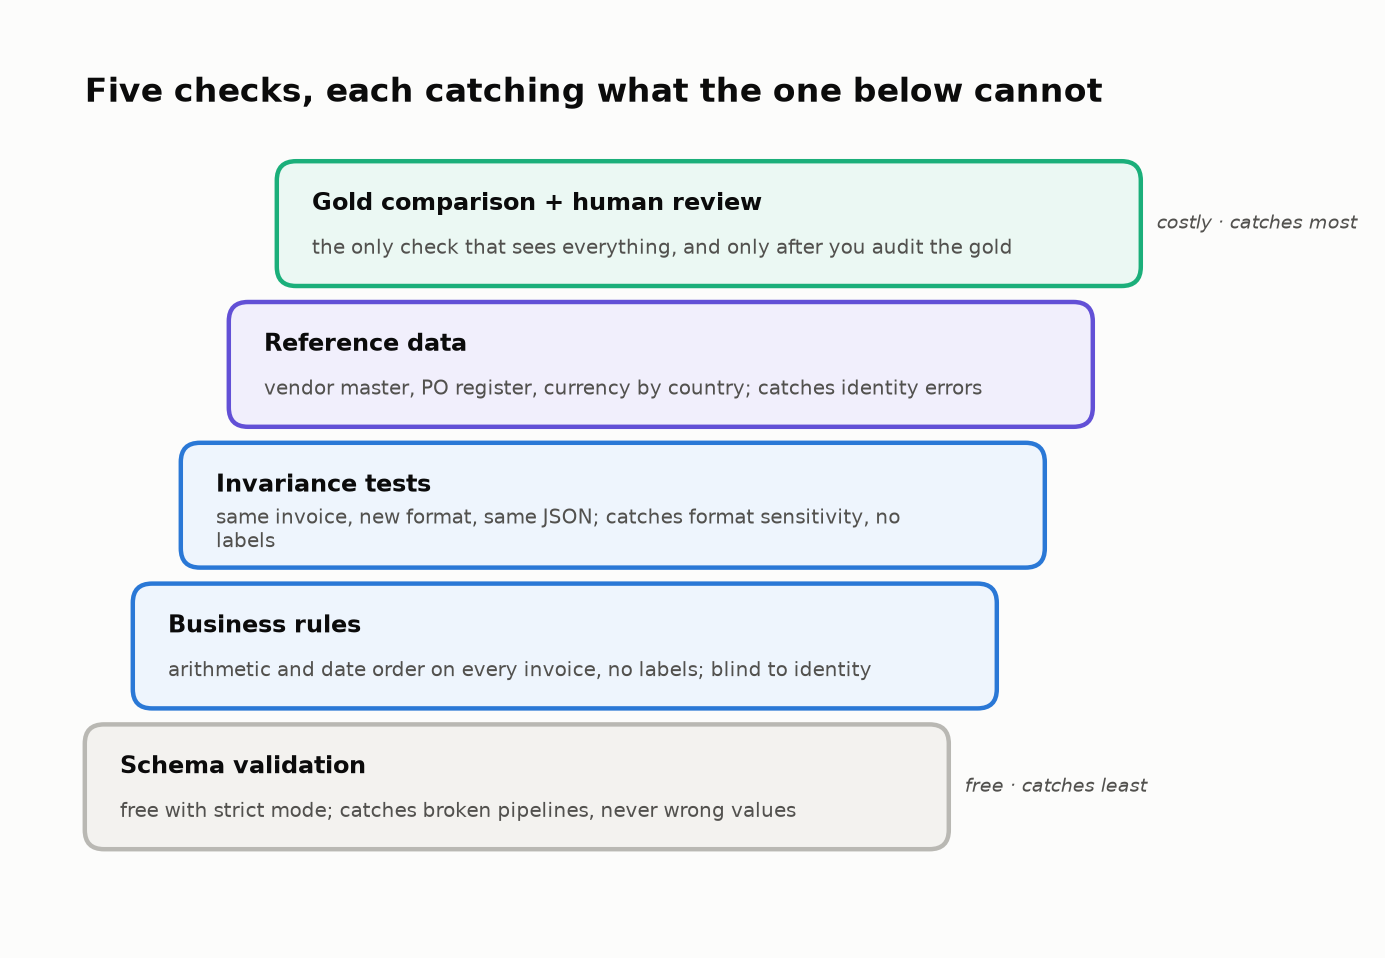
<sub>🖼️ *The lab's checks as a ladder: climb it in order, and stop reporting the bottom rung as quality.*</sub>

---

## 🏋️ Exercises

Practice with the objects from this lab: `outputs`, `GOLD_FIXED`, `SOURCES`, `validator`, `field_correct`, `supported`, `rule_check`.

### Exercise 1 — Beginner: Collect every schema error ✅
Print **all** schema errors for `LEGACY_OUTPUTS["legacy-B"]`, not just the first.

<details>
<summary>Show solution</summary>

```python
for e in validator.iter_errors(LEGACY_OUTPUTS["legacy-B"]):
    print("❌", ".".join(map(str, e.absolute_path)) or "(root)", "→", e.message)
```
</details>

### Exercise 2 — Applied: Field-level diff for one invoice 🔍
List every field where `outputs["INV-2026-0105"]` disagrees with `GOLD_FIXED`, using `field_correct`.

<details>
<summary>Show solution</summary>

```python
iid = "INV-2026-0105"
for f in FIELDS:
    if not field_correct(f, outputs[iid][f], GOLD_FIXED[iid][f]):
        print(f"❌ {f}: model={outputs[iid][f]!r}  gold={GOLD_FIXED[iid][f]!r}")
```
</details>

### Exercise 3 — Harder: Why fuzzy matching fails here 🔤
Compute `SequenceMatcher(...).ratio()` between each extracted `vendor_name` and its gold value for all 20 invoices. Is there *any* threshold that accepts every correct name and rejects `"TechParts lnc."`?

<details>
<summary>Show solution</summary>

```python
ratios = {iid: SequenceMatcher(None, outputs[iid]["vendor_name"], GOLD_FIXED[iid]["vendor_name"]).ratio() for iid in outputs}
bad = ratios["INV-2026-0104"]
good = [r for iid, r in ratios.items() if iid != "INV-2026-0104"]
print(f"typo scores {bad:.3f}; lowest legitimate match {min(good):.3f}")
print("A separating threshold exists" if min(good) > bad else "No threshold separates them: normalise instead")
```
</details>

### Exercise 4 — Stretch: Per-field hallucination dashboard 📊
Extend `null_report` to give hallucination and omission rates **per nullable field** (`due_date`, `po_number`, `notes`) with Wilson intervals. Which field would you monitor first in production? (Open-ended.)